# 02 · Regresión múltiple: el ciclo diagnóstico → corrección

**Módulo 4 · Sesión 1 · Notebook 2 de 2** — duración estimada: **70 minutos**

---

## Caso de uso

> El departamento de ventas de una empresa quiere saber **en qué canales de publicidad invertir**.
> Dispone del presupuesto destinado a **TV**, **radio** y **periódico** en 200 regiones, junto con
> las **ventas** conseguidas en cada una.
>
> Las preguntas del negocio son tres: *¿qué canales funcionan?*, *¿cuánto aporta cada euro
> invertido?* y *¿conviene repartir el presupuesto o concentrarlo?*

## Qué se aprende aquí

Este notebook es el corazón práctico de la sesión. Vamos a construir cuatro modelos, y **cada uno
nacerá de un fallo detectado en el anterior**:

| Modelo | Nace de… | Qué corrige |
|---|---|---|
| **A** `tv + radio + periodico` | El punto de partida | — |
| **B** `tv + radio` | Un predictor no significativo | Confusión entre canales |
| **C** `tv * radio` | RESET $\approx 10^{-11}$ | Falta una interacción |
| **D** `√tv * radio` | RESET $\approx 10^{-14}$ | Rendimientos decrecientes |

El resultado final: el error de predicción cae de **1.70 a 0.44** sin recolectar un solo dato
nuevo. Todo sale del diagnóstico.

> **Prerrequisito:** el notebook 01, del que se reutilizan el protocolo de 6 pasos, el marco de
> prioridades 🔴/🟡/🟢 y las funciones `panel_diagnostico()` y `diagnostico()`.

> 🔍 Las secciones marcadas así son ampliaciones opcionales.

---

## Guía de sesión para el mentor · Notebook 02

**Duración objetivo: 70 min.**

| Bloque | Contenido | Min | ¿Saltable? |
|---|---|---|---|
| 0 | Setup (mismas funciones del NB 01) | 2 | Ejecutar y seguir |
| 1–2 | EDA y datos | 6 | No |
| **3** | **Efecto marginal vs parcial: el caso del periódico** | **12** | **No — es el concepto clave** |
| 4–6 | Modelo A, VIF, comparación de modelos anidados | 10 | 🔍 la ampliación de colinealidad, sí |
| **7** | **Diagnóstico: todo falla, y hay una sola causa** | **12** | **No — es el momento central** |
| 8–10 | Interacción y transformación | 15 | 🔍 colinealidad estructural, sí |
| 11 | Heterocedasticidad: HC3 | 6 | 🔍 WLS y bootstrap, sí |
| 12–15 | Influencia, comparación y validación final | 7 | No |

### Los dos momentos de mayor impacto

- **§3 (periódico)**: un canal que "funciona" en el análisis simple y desaparece al controlar por
  radio. Es el ejemplo más limpio de por qué correlación ≠ causalidad, y tiene consecuencia
  directa de negocio: dejar de gastar en ese canal.
- **§7 → §10**: un modelo con $R^2 = 0.89$ y todo significativo resulta estar **mal especificado**.
  Al corregirlo, el error de predicción se reduce a la cuarta parte. Es el argumento definitivo de
  por qué el diagnóstico no es burocracia.

### Preguntas para lanzar al aula

- *"Si el R² subió de 0.89 a 0.97, ¿ya está bien el modelo?"* → §9: el RESET sigue en $10^{-14}$
- *"¿Por qué el periódico deja de ser significativo?"* → §3: confusión, no colinealidad (VIF ≈ 1.1)
- *"¿Podemos decirle al cliente que la TV causa ventas?"* → §15: datos observacionales

### Cierre

Termina conectando con la Sesión 2: aquí teníamos 3 predictores y pudimos diagnosticar uno a uno.
*¿Qué pasa cuando hay 100 predictores y más variables que observaciones?*

---
# Parte 0 · Preparación del entorno

## 0.1 Librerías

Trabajaremos principalmente con **`statsmodels`** y no con `scikit-learn`. La razón es conceptual,
no de gusto:

| Librería | Filosofía | Qué te da |
|---|---|---|
| `scikit-learn` | *machine learning* | Predicción. `.fit()`, `.predict()`, métricas de error. **No** da errores estándar, ni p-valores, ni tests de supuestos. |
| `statsmodels` | *estadística inferencial* | El modelo **más** todo el aparato inferencial: errores estándar, tests $t$ y $F$, intervalos, matriz de influencia, tests de diagnóstico. |

Como esta clase va de *entender* el fenómeno y no solo de predecirlo, `statsmodels` es la
herramienta correcta. Usaremos `scikit-learn` únicamente para las particiones y la validación cruzada.

In [1]:
# Tratamiento de datos
# ==============================================================================
import numpy as np
import pandas as pd

# Gráficos
# ==============================================================================
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# Estadística inferencial y modelado
# ==============================================================================
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.outliers_influence import (
    variance_inflation_factor,
    OLSInfluence,
)
from statsmodels.stats.diagnostic import (
    het_breuschpagan,      # heterocedasticidad (forma lineal)
    het_white,             # heterocedasticidad (forma general)
    het_goldfeldquandt,    # heterocedasticidad (comparación de dos submuestras)
    linear_reset,          # especificación funcional / linealidad (RESET de Ramsey)
    acorr_breusch_godfrey, # autocorrelación de orden p
    normal_ad,             # normalidad (Anderson-Darling)
)
from statsmodels.stats.stattools import durbin_watson, jarque_bera, omni_normtest
from statsmodels.graphics.gofplots import ProbPlot

# Tests y distribuciones
# ==============================================================================
from scipy import stats
from scipy.stats import pearsonr, spearmanr

# Validación
# ==============================================================================
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Utilidades
# ==============================================================================
import warnings
warnings.filterwarnings('ignore')

print(f"pandas      {pd.__version__}")
print(f"numpy       {np.__version__}")
print(f"statsmodels {sm.__version__}")
print(f"seaborn     {sns.__version__}")

pandas      3.0.5
numpy       2.5.1
statsmodels 0.14.6
seaborn     0.13.2


## 0.2 Configuración gráfica

Un detalle no cosmético: fijamos una **semilla global** para que todas las simulaciones y
remuestreos de la clase sean reproducibles. En un análisis estadístico, un resultado que no se
puede reproducir no es un resultado.

In [2]:
# Estilo gráfico coherente para toda la clase
# ==============================================================================
plt.rcParams.update({
    'figure.dpi'        : 100,
    'savefig.bbox'      : 'tight',
    'axes.grid'         : True,
    'grid.alpha'        : 0.25,
    'grid.linestyle'    : '--',
    'axes.spines.top'   : False,
    'axes.spines.right' : False,
    'axes.titlesize'    : 11,
    'axes.titleweight'  : 'bold',
    'axes.labelsize'    : 9,
    'xtick.labelsize'   : 8,
    'ytick.labelsize'   : 8,
    'legend.fontsize'   : 8,
    'figure.titlesize'  : 13,
    'figure.titleweight': 'bold',
})

# Paleta de la clase
AZUL, ROJO, VERDE, GRIS, NARANJA = '#2E5E8C', '#C1443C', '#2E8B57', '#7A7A7A', '#E08A1E'
sns.set_palette([AZUL, ROJO, VERDE, NARANJA, GRIS])

# Reproducibilidad
SEED = 1234
rng = np.random.default_rng(SEED)
np.random.seed(SEED)

pd.set_option('display.float_format', lambda v: f'{v:,.4f}')
pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 40)

print("Configuración lista · semilla =", SEED)

Configuración lista · semilla = 1234


## 0.3 Funciones auxiliares

Vamos a diagnosticar varios modelos a lo largo de la clase. Para que el diagnóstico sea
**sistemático y no selectivo** —y sobre todo para que sea **breve**— definimos tres funciones:

| Función | Qué hace | ¿Rutina? |
|---|---|---|
| `panel_diagnostico(modelo)` | Los 8 gráficos canónicos de residuos en una figura | ✅ siempre |
| `diagnostico(modelo, objetivo=...)` | **Un chequeo por supuesto**, con prioridad y acción según el objetivo | ✅ siempre |
| `resumen_modelo(modelo)` | Ficha de bondad de ajuste ($R^2$, AIC, RMSE, $R^2$ predictivo) | ✅ siempre |
| `diagnostico_completo(modelo)` | Batería exhaustiva (10 tests) | 🔍 solo si hay dudas |

> **Por qué un test por supuesto y no diez.** Si aplicamos 10 tests con $\alpha = 0.05$ sobre un
> modelo perfectamente válido, la probabilidad de que **al menos uno** salga significativo por azar
> es $1 - 0.95^{10} \approx 40\%$. Ejecutar baterías completas de forma rutinaria genera alarmas
> falsas y, peor aún, invita a elegir el test que confirma lo que queríamos concluir.
>
> El diagnóstico se resuelve **triangulando** gráfico + un test por supuesto + conocimiento del
> dominio. Los gráficos son el juez; los tests, los testigos.

In [3]:
def panel_diagnostico(modelo, titulo="Diagnóstico de residuos", figsize=(14, 10)):
    '''Los 8 gráficos canónicos de diagnóstico de un modelo OLS de statsmodels.

    1. Observado vs predicho      -> calidad global del ajuste
    2. Residuos vs ajustados      -> LINEALIDAD (y heterocedasticidad grosera)
    3. Scale-Location             -> HOMOCEDASTICIDAD
    4. Q-Q plot                   -> NORMALIDAD
    5. Histograma de residuos     -> NORMALIDAD (forma, asimetría, colas)
    6. Residuos vs orden          -> INDEPENDENCIA
    7. Residuos vs leverage       -> INFLUENCIA (con contornos de Cook)
    8. Distancia de Cook          -> INFLUENCIA (por observación)
    '''
    infl        = modelo.get_influence()
    ajustados   = modelo.fittedvalues
    residuos    = modelo.resid
    observados  = modelo.model.endog
    r_student   = infl.resid_studentized_internal   # residuos estandarizados
    leverage    = infl.hat_matrix_diag              # h_ii
    cook        = infl.cooks_distance[0]
    n, p        = int(modelo.nobs), int(modelo.df_model) + 1
    lowess      = sm.nonparametric.lowess

    fig, axes = plt.subplots(4, 2, figsize=figsize)
    ax = axes.flat

    # --- 1. Observado vs predicho -------------------------------------------
    ax[0].scatter(observados, ajustados, alpha=.5, color=AZUL, edgecolors='white', lw=.5)
    lims = [min(observados.min(), ajustados.min()), max(observados.max(), ajustados.max())]
    ax[0].plot(lims, lims, 'k--', lw=1.5)
    ax[0].set(title='1. Observado vs predicho', xlabel='Valor observado', ylabel='Valor predicho')
    ax[0].text(.05, .92, f'$R^2$ = {modelo.rsquared:.3f}', transform=ax[0].transAxes,
               fontsize=9, bbox=dict(fc='white', ec=GRIS, alpha=.8))

    # --- 2. Residuos vs ajustados (LINEALIDAD) ------------------------------
    ax[1].scatter(ajustados, residuos, alpha=.5, color=AZUL, edgecolors='white', lw=.5)
    ax[1].axhline(0, color='black', ls='--', lw=1.5)
    sm_l = lowess(residuos, ajustados, frac=.7)
    ax[1].plot(sm_l[:, 0], sm_l[:, 1], color=ROJO, lw=2, label='LOWESS')
    ax[1].legend(loc='best')
    ax[1].set(title='2. Residuos vs ajustados  →  LINEALIDAD',
              xlabel='Valor ajustado', ylabel='Residuo')

    # --- 3. Scale-Location (HOMOCEDASTICIDAD) -------------------------------
    raiz_abs = np.sqrt(np.abs(r_student))
    ax[2].scatter(ajustados, raiz_abs, alpha=.5, color=AZUL, edgecolors='white', lw=.5)
    sm_l = lowess(raiz_abs, ajustados, frac=.7)
    ax[2].plot(sm_l[:, 0], sm_l[:, 1], color=ROJO, lw=2)
    ax[2].set(title='3. Scale-Location  →  HOMOCEDASTICIDAD',
              xlabel='Valor ajustado', ylabel=r'$\sqrt{|residuo\ estandarizado|}$')

    # --- 4. Q-Q plot (NORMALIDAD) -------------------------------------------
    pp = ProbPlot(r_student, fit=True)
    pp.qqplot(line='45', ax=ax[3], color=AZUL, alpha=.5, markeredgecolor='white')
    ax[3].get_lines()[1].set_color('black'); ax[3].get_lines()[1].set_linestyle('--')
    ax[3].set(title='4. Q-Q normal  →  NORMALIDAD',
              xlabel='Cuantiles teóricos', ylabel='Cuantiles observados')

    # --- 5. Histograma de residuos ------------------------------------------
    sns.histplot(residuos, kde=True, stat='density', color=AZUL, alpha=.35,
                 line_kws={'lw': 2}, ax=ax[4])
    x_ = np.linspace(residuos.min(), residuos.max(), 200)
    ax[4].plot(x_, stats.norm.pdf(x_, residuos.mean(), residuos.std(ddof=1)),
               color=ROJO, ls='--', lw=2, label='Normal teórica')
    ax[4].legend()
    ax[4].set(title='5. Distribución de residuos', xlabel='Residuo', ylabel='Densidad')

    # --- 6. Residuos vs orden (INDEPENDENCIA) -------------------------------
    ax[5].plot(np.arange(n), residuos, marker='o', ls='-', lw=.8, ms=3.5,
               color=AZUL, alpha=.7)
    ax[5].axhline(0, color='black', ls='--', lw=1.5)
    ax[5].set(title=f'6. Residuos vs orden  →  INDEPENDENCIA (DW = {durbin_watson(residuos):.2f})',
              xlabel='Orden de la observación', ylabel='Residuo')

    # --- 7. Residuos vs leverage (INFLUENCIA) -------------------------------
    ax[6].scatter(leverage, r_student, alpha=.5, color=AZUL, edgecolors='white', lw=.5)
    ax[6].axhline(0, color='black', ls='--', lw=1)
    ax[6].axvline(2 * p / n, color=NARANJA, ls=':', lw=1.5, label=f'2p/n = {2*p/n:.3f}')
    # contornos de la distancia de Cook = 0.5 y 1
    h_grid = np.linspace(max(leverage.min(), 1e-4), leverage.max() * 1.05, 100)
    for d, ls in [(0.5, '--'), (1.0, '-')]:
        borde = np.sqrt(d * p * (1 - h_grid) / h_grid)
        ax[6].plot(h_grid, borde,  color=ROJO, ls=ls, lw=1, alpha=.8)
        ax[6].plot(h_grid, -borde, color=ROJO, ls=ls, lw=1, alpha=.8)
    ax[6].set_ylim(min(-3.5, r_student.min() * 1.15), max(3.5, r_student.max() * 1.15))
    ax[6].set_xlim(0, leverage.max() * 1.1)
    ax[6].legend(loc='lower right')
    ax[6].set(title="7. Residuos vs leverage  →  INFLUENCIA\n(líneas rojas: Cook = 0.5 y 1)",
              xlabel='Leverage $h_{ii}$', ylabel='Residuo estandarizado')

    # --- 8. Distancia de Cook -----------------------------------------------
    ax[7].vlines(np.arange(n), 0, cook, color=AZUL, alpha=.6, lw=1)
    ax[7].scatter(np.arange(n), cook, s=14, color=AZUL, zorder=3)
    ax[7].axhline(4 / n, color=ROJO, ls='--', lw=1.5, label=f'4/n = {4/n:.3f}')
    top = np.argsort(cook)[-3:]
    for i in top:
        ax[7].annotate(str(modelo.model.data.row_labels[i]), (i, cook[i]),
                       textcoords='offset points', xytext=(0, 5), fontsize=7, ha='center')
    ax[7].legend()
    ax[7].set(title="8. Distancia de Cook  →  INFLUENCIA", xlabel='Observación', ylabel="Cook's D")

    fig.suptitle(titulo, y=1.005)
    fig.tight_layout()
    plt.show()

print("Definida: panel_diagnostico(modelo)  ·  los 8 gráficos canónicos de residuos")

Definida: panel_diagnostico(modelo)  ·  los 8 gráficos canónicos de residuos


In [4]:
# Diagnóstico MÍNIMO priorizado: un chequeo por supuesto + veredicto
# ==============================================================================
def diagnostico(modelo, objetivo='inferencia', orden_con_sentido=False, alpha=0.05):
    """Chequeo mínimo de supuestos, priorizado según para qué se va a usar el modelo.

    objetivo : 'prediccion'  -> solo importa el error de predicción puntual
               'intervalos'  -> además hacen falta intervalos de predicción fiables
               'inferencia'  -> se van a interpretar coeficientes, p-valores e IC
               'causal'      -> se va a afirmar que X causa Y

    Devuelve una tabla con: qué se chequea, resultado, PRIORIDAD y qué hacer.
    La prioridad depende del objetivo: el mismo fallo puede ser irrelevante
    para predecir y bloqueante para inferir.
    """
    n, p = int(modelo.nobs), int(modelo.df_model) + 1
    res, exog = np.asarray(modelo.resid), modelo.model.exog
    F = []   # filas

    def add(supuesto, chequeo, valor, ok, prioridad, accion):
        marca = '—' if ok is None else ('✔' if ok else '✘')
        F.append({'Supuesto': supuesto, 'Chequeo': chequeo, 'Resultado': valor,
                  '¿Se cumple?': marca, 'Prioridad': prioridad, 'Qué hacer': accion})

    def fp(p):
        # ojo: nada de '<' en el texto, la tabla se renderiza como HTML
        return 'p ≈ 0' if p < 1e-16 else f'p = {p:.3g}'

    # ---- A1 LINEALIDAD / especificación --------------------------------------
    try:
        p_reset = float(linear_reset(modelo, power=2, test_type='fitted', use_f=True).pvalue)
        ok = p_reset >= alpha
        add('A1 · Linealidad', 'RESET de Ramsey', fp(p_reset), ok,
            '🟢 correcto' if ok else '🔴 BLOQUEANTE',
            'Seguir' if ok else 'Transformar / añadir interacción ANTES de leer ningún coeficiente')
    except Exception:
        add('A1 · Linealidad', 'RESET de Ramsey', 'no calculable', False, '⚪ revisar', 'Inspeccionar residuos vs ajustados')

    # ---- A2 EXOGENEIDAD (no contrastable) ------------------------------------
    add('A2 · Exogeneidad', 'NO hay test estadístico', 'requiere criterio del dominio', None,
        '🔴 crítico' if objetivo == 'causal' else '🟡 limita la lectura',
        'Solo diseño experimental o variables instrumentales lo garantizan')

    # ---- A3 HOMOCEDASTICIDAD -------------------------------------------------
    try:
        p_het = float(het_white(res, exog)[3]); test_het = 'White'
    except Exception:
        p_het = float(het_breuschpagan(res, exog)[3]); test_het = 'Breusch-Pagan'
    ok = p_het >= alpha
    if ok:
        prio, acc = '🟢 correcto', 'Seguir'
    elif objetivo == 'prediccion':
        prio, acc = '🟢 tolerable', 'No sesga β ni la predicción puntual: se puede seguir'
    else:
        prio, acc = '🟡 corregible', 'Usar errores estándar robustos HC3 (una línea de código)'
    add('A3 · Homocedasticidad', test_het, fp(p_het), ok, prio, acc)

    # ---- A4 INDEPENDENCIA ----------------------------------------------------
    dw = float(durbin_watson(res))
    if not orden_con_sentido:
        add('A4 · Independencia', 'Durbin-Watson', f'DW = {dw:.2f}', None, '⚪ no aplicable',
            'Sin orden natural (tiempo/espacio) el test no es interpretable')
    else:
        ok = 1.5 < dw < 2.5
        add('A4 · Independencia', 'Durbin-Watson', f'DW = {dw:.2f}', ok,
            '🟢 correcto' if ok else '🔴 BLOQUEANTE',
            'Seguir' if ok else 'Errores HAC (Newey-West), GLS o modelo de series temporales')

    # ---- A5 NORMALIDAD -------------------------------------------------------
    if n < 50:
        p_norm, test_norm = float(stats.shapiro(res).pvalue), 'Shapiro-Wilk'
    else:
        p_norm, test_norm = float(jarque_bera(res)[1]), 'Jarque-Bera'
    ok = p_norm >= alpha
    if ok:
        prio, acc = '🟢 correcto', 'Seguir'
    elif objetivo == 'prediccion':
        prio, acc = '🟢 tolerable', 'No afecta la predicción puntual'
    elif n >= 50:
        prio, acc = '🟢 tolerable', f'Con n = {n} el TLC protege los tests t y F'
    else:
        prio, acc = '🟡 corregible', 'Con n pequeño: bootstrap para los IC, o transformar Y'
    if (not ok) and objetivo == 'intervalos':
        prio, acc = '🟡 corregible', 'Los intervalos de PREDICCIÓN sí dependen de la normalidad'
    add('A5 · Normalidad', test_norm, fp(p_norm), ok, prio, acc)

    # ---- A6 COLINEALIDAD -----------------------------------------------------
    idx = [i for i, nm in enumerate(modelo.model.exog_names) if nm.lower() != 'intercept']
    if len(idx) > 1:
        vifs = {modelo.model.exog_names[i]: variance_inflation_factor(exog, i) for i in idx}
        peor, vmax = max(vifs.items(), key=lambda kv: kv[1])
        ok = vmax < 10
        if ok:
            prio, acc = '🟢 correcto', 'Seguir'
        elif objetivo == 'prediccion':
            prio, acc = '🟢 tolerable', 'La colinealidad no afecta a la predicción'
        else:
            prio, acc = '🟡 corregible', 'Centrar (si es estructural), eliminar/combinar o regularizar'
        add('A6 · Colinealidad', 'VIF máximo', f'{peor}: {vmax:.1f}', ok, prio, acc)

    # ---- INFLUENCIA ----------------------------------------------------------
    cook = modelo.get_influence().cooks_distance[0]
    n_alto, max_cook = int((cook > 4 / n).sum()), float(cook.max())
    ok = (max_cook < 1) and (n_alto <= 0.05 * n)
    add('Influencia', "Cook's D", f'máx = {max_cook:.2f} · {n_alto} obs > 4/n', ok,
        '🟢 correcto' if ok else '🟡 revisar',
        'Seguir' if ok else 'Análisis de sensibilidad: reajustar sin ellas y comparar conclusiones')

    tabla = pd.DataFrame(F)

    # ---- VEREDICTO -----------------------------------------------------------
    fallan = [f for f in F if f['¿Se cumple?'] == '✘']
    n_rojo = sum('🔴' in f['Prioridad'] for f in fallan)
    n_ambar = sum('🟡' in f['Prioridad'] for f in fallan)
    print(f"OBJETIVO: {objetivo.upper()}   ·   n = {n}   ·   k = {p-1}")
    if n_rojo:
        print(f"VEREDICTO: ⛔ NO PROCEDE tal cual — {n_rojo} problema(s) BLOQUEANTE(S).")
        print("           Corregir la especificación y volver a diagnosticar. Los coeficientes")
        print("           actuales están sesgados: no tiene sentido interpretarlos ni corregir")
        print("           los errores estándar todavía.")
    elif n_ambar:
        print(f"VEREDICTO: ⚠️  PROCEDE CON CORRECCIONES — {n_ambar} punto(s) a corregir (columna 'Qué hacer').")
        print("           Los coeficientes son válidos; hay que ajustar cómo se mide su incertidumbre.")
    else:
        print("VEREDICTO: ✅ PROCEDE — no hay violaciones relevantes para este objetivo.")

    return (tabla.style.hide(axis='index').set_properties(**{'text-align': 'left'})
            .apply(lambda s: ['background-color:#fdecea; font-weight:bold' if '🔴' in str(v)
                              else ('background-color:#fff6e5' if '🟡' in str(v)
                                    else ('background-color:#eaf5ea' if '🟢' in str(v) else ''))
                              for v in s], subset=['Prioridad']))


print("Definida: diagnostico(modelo, objetivo=...)  ·  el chequeo que se usa en toda la clase")

Definida: diagnostico(modelo, objetivo=...)  ·  el chequeo que se usa en toda la clase


In [5]:
# 🔍 AMPLIACIÓN (opcional): batería exhaustiva de tests
# ==============================================================================
# Se usa solo cuando el diagnóstico mínimo deja dudas o cuando hay que documentar
# un modelo formalmente. En el flujo normal NO hace falta.
def diagnostico_completo(modelo, alpha=0.05, orden_con_sentido=False):
    """Todos los tests disponibles por supuesto. Útil como referencia, no como rutina."""
    res, exog = np.asarray(modelo.resid), modelo.model.exog
    filas = []

    def add(sup, test, h0, est, p, aplica=True):
        filas.append({'Supuesto': sup, 'Test': test, 'H0': h0, 'Estadístico': est, 'p-valor': p,
                      'Decisión': ('— no aplicable —' if not aplica else
                                   ('✘ se rechaza H0' if p < alpha else '✔ no se rechaza H0'))})

    for pot in (2, 3):
        r = linear_reset(modelo, power=pot, test_type='fitted', use_f=True)
        add('Linealidad', f'RESET (hasta ŷ^{pot})', 'forma funcional correcta',
            float(r.statistic), float(r.pvalue))

    bp = het_breuschpagan(res, exog); add('Homocedasticidad', 'Breusch-Pagan', 'varianza constante', bp[0], bp[1])
    try:
        wh = het_white(res, exog); add('Homocedasticidad', 'White', 'varianza constante', wh[0], wh[1])
    except Exception:
        add('Homocedasticidad', 'White', 'varianza constante', np.nan, np.nan, aplica=False)
    orden = np.argsort(np.asarray(modelo.fittedvalues))
    gq = het_goldfeldquandt(np.asarray(modelo.model.endog)[orden], exog[orden], alternative='two-sided')
    add('Homocedasticidad', 'Goldfeld-Quandt (por ŷ)', 'varianza constante', gq[0], gq[1])

    sh = stats.shapiro(res);      add('Normalidad', 'Shapiro-Wilk', 'residuos normales', sh.statistic, sh.pvalue)
    jb = jarque_bera(res);        add('Normalidad', 'Jarque-Bera', 'residuos normales', jb[0], jb[1])
    om = omni_normtest(res);      add('Normalidad', "D'Agostino (Omnibus)", 'residuos normales', om[0], om[1])
    ad = normal_ad(res);          add('Normalidad', 'Anderson-Darling', 'residuos normales', ad[0], ad[1])

    filas.append({'Supuesto': 'Independencia', 'Test': 'Durbin-Watson', 'H0': 'sin autocorrelación',
                  'Estadístico': durbin_watson(res), 'p-valor': np.nan,
                  'Decisión': ('≈2 es lo esperable' if orden_con_sentido else '— no aplicable (sin orden) —')})
    try:
        bg = acorr_breusch_godfrey(modelo, nlags=2)
        add('Independencia', 'Breusch-Godfrey (2 lags)', 'sin autocorrelación', bg[0], bg[1],
            aplica=orden_con_sentido)
    except Exception:
        pass

    return (pd.DataFrame(filas).style.format({'Estadístico': '{:,.4f}', 'p-valor': '{:.3e}'}, na_rep='—')
            .hide(axis='index').set_properties(**{'text-align': 'left'}))


print("Definida: diagnostico_completo(modelo)  ·  solo para ampliación / documentación formal")

Definida: diagnostico_completo(modelo)  ·  solo para ampliación / documentación formal


In [6]:
def resumen_modelo(modelo, nombre='modelo', datos_test=None, y_test=None):
    '''Ficha compacta de bondad de ajuste. Si se pasa un conjunto de test,
    añade el RMSE fuera de muestra.'''
    n     = int(modelo.nobs)
    res   = np.asarray(modelo.resid)
    rmse  = np.sqrt(np.mean(res ** 2))
    # PRESS y R2 predictivo (validación leave-one-out analítica)
    h     = modelo.get_influence().hat_matrix_diag
    press = np.sum((res / (1 - h)) ** 2)
    sst   = np.sum((modelo.model.endog - modelo.model.endog.mean()) ** 2)

    ficha = {
        'modelo'          : nombre,
        'n'               : n,
        'k (predictores)' : int(modelo.df_model),
        'R²'              : modelo.rsquared,
        'R² ajustado'     : modelo.rsquared_adj,
        'R² predictivo'   : 1 - press / sst,
        'F'               : modelo.fvalue,
        'p(F)'            : modelo.f_pvalue,
        'AIC'             : modelo.aic,
        'BIC'             : modelo.bic,
        'RMSE train'      : rmse,
        'RMSE LOOCV'      : np.sqrt(press / n),
    }
    if datos_test is not None and y_test is not None:
        pred = modelo.predict(datos_test)
        ficha['RMSE test'] = float(np.sqrt(np.mean((np.asarray(y_test) - pred) ** 2)))
    return pd.Series(ficha)

print("Funciones auxiliares definidas: panel_diagnostico(), tabla_diagnostico(), resumen_modelo()")

Funciones auxiliares definidas: panel_diagnostico(), tabla_diagnostico(), resumen_modelo()


---
---
# Caso: inversión publicitaria → ventas

## 1. Contexto y datos

> El departamento de ventas de una empresa quiere estudiar la influencia de la publicidad en tres
> canales sobre las ventas de un producto. Se dispone del presupuesto (en millones) destinado a
> **TV**, **radio** y **periódico** en 200 regiones, junto con las **ventas** conseguidas en cada una.

| Elemento | En este caso |
|---|---|
| Unidad de observación | La región de mercado |
| Variable respuesta $Y$ | `ventas` (millones) |
| Predictores | `tv`, `radio`, `periodico` (presupuesto en millones) |
| Tamaño muestral | $n = 200$ |
| Naturaleza | Observacional |

Con $n = 200$ y 3 predictores estamos en una situación mucho más cómoda que en el Caso 1: el TLC
nos protege parcialmente frente a la no normalidad, y una partición train/test es defendible.

**Aquí sí usaremos train (80%) / test (20%)**, porque el objetivo incluye comparar varias
especificaciones del modelo. Cuando se compara y se selecciona entre modelos, se introduce un sesgo
optimista si se evalúa sobre los mismos datos que se usan para elegir. El conjunto de test quedará
**intacto hasta la última sección** y solo se usará una vez.

In [7]:
# Datos: 200 regiones, inversión publicitaria y ventas
# ==============================================================================
tv = [230.1, 44.5, 17.2, 151.5, 180.8, 8.7, 57.5, 120.2, 8.6, 199.8, 66.1, 214.7,
      23.8, 97.5, 204.1, 195.4, 67.8, 281.4, 69.2, 147.3, 218.4, 237.4, 13.2,
      228.3, 62.3, 262.9, 142.9, 240.1, 248.8, 70.6, 292.9, 112.9, 97.2, 265.6,
      95.7, 290.7, 266.9, 74.7, 43.1, 228.0, 202.5, 177.0, 293.6, 206.9, 25.1,
      175.1, 89.7, 239.9, 227.2, 66.9, 199.8, 100.4, 216.4, 182.6, 262.7, 198.9,
      7.3, 136.2, 210.8, 210.7, 53.5, 261.3, 239.3, 102.7, 131.1, 69.0, 31.5,
      139.3, 237.4, 216.8, 199.1, 109.8, 26.8, 129.4, 213.4, 16.9, 27.5, 120.5,
      5.4, 116.0, 76.4, 239.8, 75.3, 68.4, 213.5, 193.2, 76.3, 110.7, 88.3, 109.8,
      134.3, 28.6, 217.7, 250.9, 107.4, 163.3, 197.6, 184.9, 289.7, 135.2, 222.4,
      296.4, 280.2, 187.9, 238.2, 137.9, 25.0, 90.4, 13.1, 255.4, 225.8, 241.7, 175.7,
      209.6, 78.2, 75.1, 139.2, 76.4, 125.7, 19.4, 141.3, 18.8, 224.0, 123.1, 229.5,
      87.2, 7.8, 80.2, 220.3, 59.6, 0.7, 265.2, 8.4, 219.8, 36.9, 48.3, 25.6, 273.7,
      43.0, 184.9, 73.4, 193.7, 220.5, 104.6, 96.2, 140.3, 240.1, 243.2, 38.0, 44.7,
      280.7, 121.0, 197.6, 171.3, 187.8, 4.1, 93.9, 149.8, 11.7, 131.7, 172.5, 85.7,
      188.4, 163.5, 117.2, 234.5, 17.9, 206.8, 215.4, 284.3, 50.0, 164.5, 19.6, 168.4,
      222.4, 276.9, 248.4, 170.2, 276.7, 165.6, 156.6, 218.5, 56.2, 287.6, 253.8, 205.0,
      139.5, 191.1, 286.0, 18.7, 39.5, 75.5, 17.2, 166.8, 149.7, 38.2, 94.2, 177.0,
      283.6, 232.1]

radio = [37.8, 39.3, 45.9, 41.3, 10.8, 48.9, 32.8, 19.6, 2.1, 2.6, 5.8, 24.0, 35.1,
         7.6, 32.9, 47.7, 36.6, 39.6, 20.5, 23.9, 27.7, 5.1, 15.9, 16.9, 12.6, 3.5,
         29.3, 16.7, 27.1, 16.0, 28.3, 17.4, 1.5, 20.0, 1.4, 4.1, 43.8, 49.4, 26.7,
         37.7, 22.3, 33.4, 27.7, 8.4, 25.7, 22.5, 9.9, 41.5, 15.8, 11.7, 3.1, 9.6,
         41.7, 46.2, 28.8, 49.4, 28.1, 19.2, 49.6, 29.5, 2.0, 42.7, 15.5, 29.6, 42.8,
         9.3, 24.6, 14.5, 27.5, 43.9, 30.6, 14.3, 33.0, 5.7, 24.6, 43.7, 1.6, 28.5,
         29.9, 7.7, 26.7, 4.1, 20.3, 44.5, 43.0, 18.4, 27.5, 40.6, 25.5, 47.8, 4.9,
         1.5, 33.5, 36.5, 14.0, 31.6, 3.5, 21.0, 42.3, 41.7, 4.3, 36.3, 10.1, 17.2,
         34.3, 46.4, 11.0, 0.3, 0.4, 26.9, 8.2, 38.0, 15.4, 20.6, 46.8, 35.0, 14.3,
         0.8, 36.9, 16.0, 26.8, 21.7, 2.4, 34.6, 32.3, 11.8, 38.9, 0.0, 49.0, 12.0,
         39.6, 2.9, 27.2, 33.5, 38.6, 47.0, 39.0, 28.9, 25.9, 43.9, 17.0, 35.4, 33.2,
         5.7, 14.8, 1.9, 7.3, 49.0, 40.3, 25.8, 13.9, 8.4, 23.3, 39.7, 21.1, 11.6, 43.5,
         1.3, 36.9, 18.4, 18.1, 35.8, 18.1, 36.8, 14.7, 3.4, 37.6, 5.2, 23.6, 10.6, 11.6,
         20.9, 20.1, 7.1, 3.4, 48.9, 30.2, 7.8, 2.3, 10.0, 2.6, 5.4, 5.7, 43.0, 21.3, 45.1,
         2.1, 28.7, 13.9, 12.1, 41.1, 10.8, 4.1, 42.0, 35.6, 3.7, 4.9, 9.3, 42.0, 8.6]

periodico = [69.2, 45.1, 69.3, 58.5, 58.4, 75.0, 23.5, 11.6, 1.0, 21.2, 24.2, 4.0,
             65.9, 7.2, 46.0, 52.9, 114.0, 55.8, 18.3, 19.1, 53.4, 23.5, 49.6, 26.2,
             18.3, 19.5, 12.6, 22.9, 22.9, 40.8, 43.2, 38.6, 30.0, 0.3, 7.4, 8.5, 5.0,
             45.7, 35.1, 32.0, 31.6, 38.7, 1.8, 26.4, 43.3, 31.5, 35.7, 18.5, 49.9,
             36.8, 34.6, 3.6, 39.6, 58.7, 15.9, 60.0, 41.4, 16.6, 37.7, 9.3, 21.4, 54.7,
             27.3, 8.4, 28.9, 0.9, 2.2, 10.2, 11.0, 27.2, 38.7, 31.7, 19.3, 31.3, 13.1,
             89.4, 20.7, 14.2, 9.4, 23.1, 22.3, 36.9, 32.5, 35.6, 33.8, 65.7, 16.0, 63.2,
             73.4, 51.4, 9.3, 33.0, 59.0, 72.3, 10.9, 52.9, 5.9, 22.0, 51.2, 45.9, 49.8,
             100.9, 21.4, 17.9, 5.3, 59.0, 29.7, 23.2, 25.6, 5.5, 56.5, 23.2, 2.4, 10.7,
             34.5, 52.7, 25.6, 14.8, 79.2, 22.3, 46.2, 50.4, 15.6, 12.4, 74.2, 25.9, 50.6,
             9.2, 3.2, 43.1, 8.7, 43.0, 2.1, 45.1, 65.6, 8.5, 9.3, 59.7, 20.5, 1.7, 12.9,
             75.6, 37.9, 34.4, 38.9, 9.0, 8.7, 44.3, 11.9, 20.6, 37.0, 48.7, 14.2, 37.7,
             9.5, 5.7, 50.5, 24.3, 45.2, 34.6, 30.7, 49.3, 25.6, 7.4, 5.4, 84.8, 21.6, 19.4,
             57.6, 6.4, 18.4, 47.4, 17.0, 12.8, 13.1, 41.8, 20.3, 35.2, 23.7, 17.6, 8.3,
             27.4, 29.7, 71.8, 30.0, 19.6, 26.6, 18.2, 3.7, 23.4, 5.8, 6.0, 31.6, 3.6, 6.0,
             13.8, 8.1, 6.4, 66.2, 8.7]

ventas = [22.1, 10.4, 9.3, 18.5, 12.9, 7.2, 11.8, 13.2, 4.8, 10.6, 8.6, 17.4, 9.2, 9.7,
          19.0, 22.4, 12.5, 24.4, 11.3, 14.6, 18.0, 12.5, 5.6, 15.5, 9.7, 12.0, 15.0, 15.9,
          18.9, 10.5, 21.4, 11.9, 9.6, 17.4, 9.5, 12.8, 25.4, 14.7, 10.1, 21.5, 16.6, 17.1,
          20.7, 12.9, 8.5, 14.9, 10.6, 23.2, 14.8, 9.7, 11.4, 10.7, 22.6, 21.2, 20.2, 23.7,
          5.5, 13.2, 23.8, 18.4, 8.1, 24.2, 15.7, 14.0, 18.0, 9.3, 9.5, 13.4, 18.9, 22.3,
          18.3, 12.4, 8.8, 11.0, 17.0, 8.7, 6.9, 14.2, 5.3, 11.0, 11.8, 12.3, 11.3, 13.6,
          21.7, 15.2, 12.0, 16.0, 12.9, 16.7, 11.2, 7.3, 19.4, 22.2, 11.5, 16.9, 11.7, 15.5,
          25.4, 17.2, 11.7, 23.8, 14.8, 14.7, 20.7, 19.2, 7.2, 8.7, 5.3, 19.8, 13.4, 21.8,
          14.1, 15.9, 14.6, 12.6, 12.2, 9.4, 15.9, 6.6, 15.5, 7.0, 11.6, 15.2, 19.7, 10.6,
          6.6, 8.8, 24.7, 9.7, 1.6, 12.7, 5.7, 19.6, 10.8, 11.6, 9.5, 20.8, 9.6, 20.7, 10.9,
          19.2, 20.1, 10.4, 11.4, 10.3, 13.2, 25.4, 10.9, 10.1, 16.1, 11.6, 16.6, 19.0, 15.6,
          3.2, 15.3, 10.1, 7.3, 12.9, 14.4, 13.3, 14.9, 18.0, 11.9, 11.9, 8.0, 12.2, 17.1,
          15.0, 8.4, 14.5, 7.6, 11.7, 11.5, 27.0, 20.2, 11.7, 11.8, 12.6, 10.5, 12.2, 8.7,
          26.2, 17.6, 22.6, 10.3, 17.3, 15.9, 6.7, 10.8, 9.9, 5.9, 19.6, 17.3, 7.6, 9.7, 12.8,
          25.5, 13.4]

publicidad = pd.DataFrame({'tv': tv, 'radio': radio,
                           'periodico': periodico, 'ventas': ventas})
publicidad.head(3)

,tv,radio,periodico,ventas
0,230.1000,37.8000,69.2000,22.1000
1,44.5000,39.3000,45.1000,10.4000
2,17.2000,45.9000,69.3000,9.3000


In [8]:
# Partición train / test  (el test NO se toca hasta la sección 14)
# ==============================================================================
train, test = train_test_split(publicidad, train_size=0.8, random_state=SEED, shuffle=True)
train = train.reset_index(drop=True)
test  = test.reset_index(drop=True)

print(f"Entrenamiento: {train.shape[0]} regiones   ·   Test: {test.shape[0]} regiones\n")
display(publicidad.describe().T.assign(CV=lambda d: d['std'] / d['mean']).round(3))
print("Valores ausentes:", publicidad.isna().sum().sum())

Entrenamiento: 160 regiones   ·   Test: 40 regiones



,count,mean,std,min,25%,50%,75%,max,CV
tv,200.0000,147.0420,85.8540,0.7000,74.3750,149.7500,218.8250,296.4000,0.5840
radio,200.0000,23.2640,14.8470,0.0000,9.9750,22.9000,36.5250,49.6000,0.6380
periodico,200.0000,30.5540,21.7790,0.3000,12.7500,25.7500,45.1000,114.0000,0.7130
ventas,200.0000,14.0220,5.2170,1.6000,10.3750,12.9000,17.4000,27.0000,0.3720


Valores ausentes: 0


## 2. Análisis exploratorio multivariante

En regresión múltiple el EDA tiene un objetivo adicional respecto al caso simple: estudiar las
relaciones **entre predictores**, porque de ellas dependen la interpretación de los coeficientes
(efectos parciales) y la estabilidad numérica del ajuste (colinealidad).

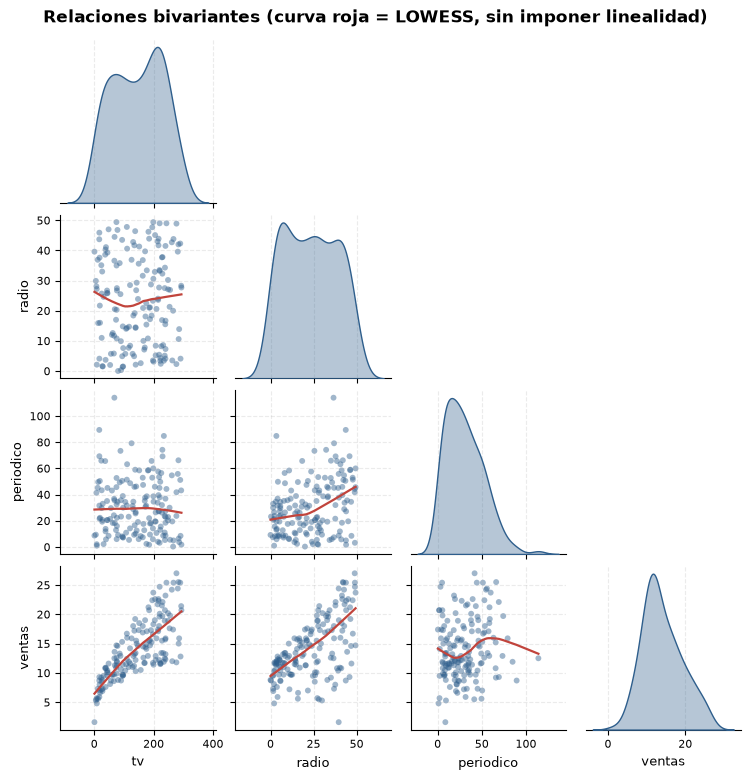

In [9]:
# Matriz de dispersión con densidades y regresiones
# ==============================================================================
g = sns.pairplot(train, corner=True, diag_kind='kde', height=1.9,
                 plot_kws=dict(s=18, alpha=.45, color=AZUL, edgecolor='none'),
                 diag_kws=dict(color=AZUL, fill=True, alpha=.35))
g.map_lower(sns.regplot, scatter=False, lowess=True, line_kws=dict(color=ROJO, lw=1.6))
g.figure.suptitle('Relaciones bivariantes (curva roja = LOWESS, sin imponer linealidad)',
                  y=1.02, fontsize=12, fontweight='bold')
plt.show()

variable_1,variable_2,r,|r|,p-valor
tv,ventas,0.7634,0.7634,8.39e-32
radio,ventas,0.5782,0.5782,1.18e-15
radio,periodico,0.3330,0.3330,1.68e-05
periodico,ventas,0.1629,0.1629,3.95e-02
tv,periodico,-0.0422,0.0422,5.96e-01
tv,radio,0.0273,0.0273,7.32e-01


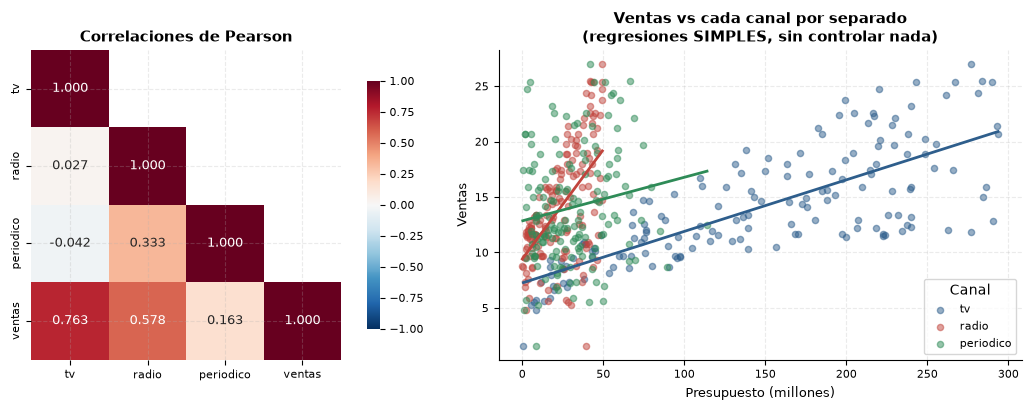

In [10]:
# Correlaciones: matriz, formato tidy y significación
# ==============================================================================
def tidy_corr(df, metodo='pearson'):
    '''Matriz de correlación en formato largo, con p-valores, ordenada por |r|.'''
    cols = df.select_dtypes(include=np.number).columns
    filas = []
    for i, a in enumerate(cols):
        for b in cols[i+1:]:
            r_, p_ = (pearsonr(df[a], df[b]) if metodo == 'pearson' else spearmanr(df[a], df[b]))[:2]
            filas.append({'variable_1': a, 'variable_2': b, 'r': r_, '|r|': abs(r_), 'p-valor': p_})
    return pd.DataFrame(filas).sort_values('|r|', ascending=False)

corr_matrix = train.corr(numeric_only=True)
display(tidy_corr(train).style.format({'r': '{:.4f}', '|r|': '{:.4f}', 'p-valor': '{:.2e}'})
        .background_gradient(subset=['|r|'], cmap='Blues').hide(axis='index'))

fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.2))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.3f', vmin=-1, vmax=1, center=0,
            cmap='RdBu_r', square=True, cbar_kws={'shrink': .8}, ax=ax[0],
            annot_kws={'size': 9})
ax[0].set_title('Correlaciones de Pearson')

for col, c in zip(['tv', 'radio', 'periodico'], [AZUL, ROJO, VERDE]):
    ax[1].scatter(train[col], train.ventas, s=20, alpha=.5, color=c, label=col)
    z = np.polyfit(train[col], train.ventas, 1)
    xg = np.linspace(train[col].min(), train[col].max(), 50)
    ax[1].plot(xg, np.polyval(z, xg), color=c, lw=2)
ax[1].legend(title='Canal')
ax[1].set(title='Ventas vs cada canal por separado\n(regresiones SIMPLES, sin controlar nada)',
          xlabel='Presupuesto (millones)', ylabel='Ventas')
plt.tight_layout(); plt.show()

### Lo que ya se ve en el EDA

1. `tv` es el predictor más correlacionado con `ventas` ($r \approx 0.78$), seguido de `radio`
   ($r \approx 0.58$) y `periodico` ($r \approx 0.16$).
2. **`radio` y `periodico` están correlacionados entre sí** ($r \approx 0.33$). Guarda este dato:
   es la clave de la sección 3.3.
3. En el gráfico de `ventas` vs `tv` se aprecia algo que será central más adelante: la nube no es
   una banda de anchura constante, sino que **se abre en abanico**, y la relación parece
   **saturarse** en presupuestos altos. Dos pistas tempranas de que el modelo lineal simple no será
   suficiente.

---

## 3. Efecto marginal vs efecto parcial: el caso de `periodico`

Aquí aparece uno de los conceptos más importantes —y peor entendidos— de la regresión múltiple.

En una regresión **simple**, $\beta_1$ mide la asociación **marginal** (o bruta) entre $X$ e $Y$.
En una regresión **múltiple**, cada $\beta_j$ mide el efecto **parcial**:

> el cambio esperado en $Y$ ante un incremento unitario de $X_j$, **manteniendo constantes todos
> los demás predictores del modelo**.

Son cantidades distintas y pueden discrepar radicalmente. Veámoslo.

In [11]:
# El mismo predictor, dos estimaciones muy distintas
# ==============================================================================
m_periodico_simple = smf.ols('ventas ~ periodico', data=train).fit()
m_completo         = smf.ols('ventas ~ tv + radio + periodico', data=train).fit()

comp = pd.DataFrame({
    'Modelo'  : ['SIMPLE: ventas ~ periodico', 'MÚLTIPLE: ventas ~ tv + radio + periodico'],
    'β̂(periodico)': [m_periodico_simple.params['periodico'], m_completo.params['periodico']],
    'SE'      : [m_periodico_simple.bse['periodico'], m_completo.bse['periodico']],
    't'       : [m_periodico_simple.tvalues['periodico'], m_completo.tvalues['periodico']],
    'p-valor' : [m_periodico_simple.pvalues['periodico'], m_completo.pvalues['periodico']],
    'Conclusión': ['SIGNIFICATIVO (p < 0.05)', 'NO significativo'],
})
display(comp.style.format({'β̂(periodico)': '{:.4f}', 'SE': '{:.4f}', 't': '{:.3f}',
                           'p-valor': '{:.4f}'}).hide(axis='index'))

# Correlación simple vs correlación parcial
r_simple = pearsonr(train.periodico, train.ventas)
res_v = smf.ols('ventas ~ tv + radio', data=train).fit().resid      # ventas sin la parte explicada por tv y radio
res_p = smf.ols('periodico ~ tv + radio', data=train).fit().resid   # periodico sin la parte explicada por tv y radio
r_parcial = pearsonr(res_p, res_v)

print(f"Correlación SIMPLE  periodico–ventas            : r = {r_simple.statistic:.4f}  (p = {r_simple.pvalue:.4f})")
print(f"Correlación PARCIAL periodico–ventas | tv, radio: r = {r_parcial.statistic:.4f}  (p = {r_parcial.pvalue:.4f})")
print(f"\nCorrelación radio–periodico: r = {pearsonr(train.radio, train.periodico).statistic:.4f}"
      f"  (p = {pearsonr(train.radio, train.periodico).pvalue:.2e})")

Modelo,β̂(periodico),SE,t,p-valor,Conclusión
SIMPLE: ventas ~ periodico,0.0393,0.0189,2.076,0.0395,SIGNIFICATIVO (p < 0.05)
MÚLTIPLE: ventas ~ tv + radio + periodico,0.0024,0.0067,0.355,0.7228,NO significativo


Correlación SIMPLE  periodico–ventas            : r = 0.1629  (p = 0.0395)
Correlación PARCIAL periodico–ventas | tv, radio: r = 0.0284  (p = 0.7211)

Correlación radio–periodico: r = 0.3330  (p = 1.68e-05)


### La explicación: confusión (*confounding*)

```
                periodico  ─────────?─────────►  ventas
                    ▲                              ▲
                    │                              │
                    └──────  radio  ───────────────┘
                          r = 0.33            efecto real y fuerte
```

Las regiones donde se invierte más en periódico son también las regiones donde se invierte más en
radio ($r = 0.33$). Y la radio **sí** aumenta las ventas. Por tanto, en una regresión simple,
`periodico` "hereda" parte del efecto de `radio` y aparece como significativo.

Al controlar por `radio` en el modelo múltiple, esa asociación prestada desaparece: la correlación
parcial cae de 0.163 a **0.028** y el p-valor pasa de 0.040 a 0.721.

> **Traducción al negocio:** invertir en periódico no aumenta las ventas. Lo que ocurre es que las
> empresas que invierten en periódico también invierten en radio, y **es la radio la que vende**.
> Un análisis que se hubiese quedado en la regresión simple habría recomendado seguir gastando en
> periódico.

Este es el mecanismo estadístico detrás de la **paradoja de Simpson** y la razón profunda por la
que "correlación no implica causalidad": la correlación marginal mezcla el efecto directo con
todos los caminos indirectos a través de variables correlacionadas.

> ⚠️ **Y el aviso simétrico:** el efecto parcial solo está limpio de los confusores **que están en
> el modelo**. Si existe una variable relevante no medida (tamaño del mercado, competencia,
> estacionalidad), el supuesto A2 sigue violado y ningún $\beta_j$ es interpretable causalmente.
> El control estadístico es tan bueno como la lista de variables que se te ocurrió medir.

### Gráficos de regresión parcial (*added-variable plots*)

El **added-variable plot** hace visible el efecto parcial. Para el predictor $X_j$:

1. Se regresa $Y$ sobre todos los predictores **excepto** $X_j$ → residuos $e_Y$.
2. Se regresa $X_j$ sobre todos los demás predictores → residuos $e_{X_j}$.
3. Se representa $e_Y$ frente a $e_{X_j}$.

La pendiente de esa nube es **exactamente** $\hat\beta_j$ del modelo múltiple (teorema de
Frisch-Waugh-Lovell). Es decir: la regresión múltiple no es magia, es una secuencia de regresiones
simples sobre variables "limpiadas" del efecto de las demás.

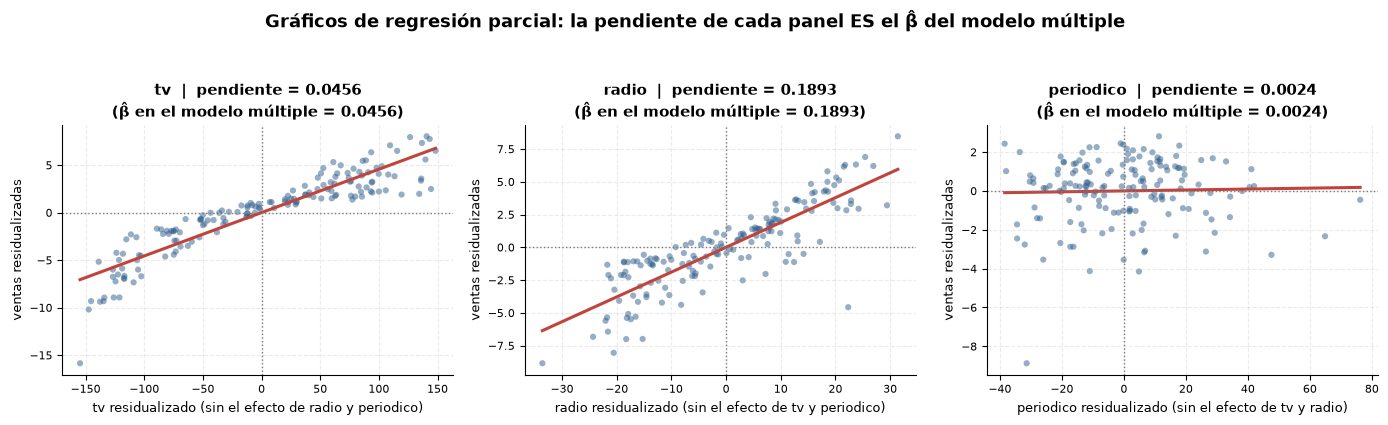

Pendiente del added-variable plot de 'periodico' : 0.002375
β̂(periodico) en el modelo múltiple              : 0.002375
→ Idénticos (teorema de Frisch-Waugh-Lovell)


In [12]:
# Added-variable plots (regresión parcial)
# ==============================================================================
predictores = ['tv', 'radio', 'periodico']
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, var in zip(axes, predictores):
    otros = [v for v in predictores if v != var]
    # residuos de Y y de X_j tras eliminar el efecto de los demás predictores
    e_y = smf.ols(f"ventas ~ {' + '.join(otros)}", data=train).fit().resid
    e_x = smf.ols(f"{var} ~ {' + '.join(otros)}", data=train).fit().resid
    pend = smf.ols('e_y ~ e_x', data=pd.DataFrame({'e_y': e_y, 'e_x': e_x})).fit()

    ax.scatter(e_x, e_y, s=20, alpha=.5, color=AZUL, edgecolors='none')
    xg = np.linspace(e_x.min(), e_x.max(), 50)
    ax.plot(xg, pend.params['Intercept'] + pend.params['e_x'] * xg, color=ROJO, lw=2.2)
    ax.axhline(0, color=GRIS, ls=':', lw=1); ax.axvline(0, color=GRIS, ls=':', lw=1)
    titulo = (f'{var}  |  pendiente = {pend.params["e_x"]:.4f}'
              + chr(10) + f'(β̂ en el modelo múltiple = {m_completo.params[var]:.4f})')
    ax.set(title=titulo,
           xlabel=f'{var} residualizado (sin el efecto de {" y ".join(otros)})',
           ylabel='ventas residualizadas')

fig.suptitle('Gráficos de regresión parcial: la pendiente de cada panel ES el β̂ del modelo múltiple',
             y=1.05)
fig.tight_layout(); plt.show()

# Comprobación numérica del teorema de Frisch-Waugh-Lovell
pendiente_avp = smf.ols('res_v ~ res_p', data=pd.DataFrame({'res_v': res_v, 'res_p': res_p})).fit()
print(f"Pendiente del added-variable plot de 'periodico' : {pendiente_avp.params['res_p']:.6f}")
print(f"β̂(periodico) en el modelo múltiple              : {m_completo.params['periodico']:.6f}")
print("→ Idénticos (teorema de Frisch-Waugh-Lovell)")

## 4. Modelo A: todos los predictores

Empezamos por el modelo más natural: los tres canales como predictores aditivos.
Es el punto de partida, no la respuesta.

In [13]:
modelo_A = smf.ols('ventas ~ tv + radio + periodico', data=train).fit()
print(modelo_A.summary())

                            OLS Regression Results                            
Dep. Variable:                 ventas   R-squared:                       0.894
Model:                            OLS   Adj. R-squared:                  0.892
Method:                 Least Squares   F-statistic:                     437.8
Date:                Tue, 04 Aug 2026   Prob (F-statistic):           1.01e-75
Time:                        19:35:16   Log-Likelihood:                -308.29
No. Observations:                 160   AIC:                             624.6
Df Residuals:                     156   BIC:                             636.9
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      2.8497      0.365      7.803      0.0

### Lectura del modelo A

- **Test F global**: $F = 437.8$ con $p \approx 10^{-75}$. Rechazamos que los tres coeficientes sean
  simultáneamente nulos: el modelo, en bloque, explica las ventas.
- $R^2 = 0.894$: el modelo reproduce el 89.4% de la varianza de `ventas` en la muestra de
  entrenamiento.
- **`tv`**: $\hat\beta = 0.0456$. Manteniendo constantes radio y periódico, cada millón adicional
  invertido en TV se asocia con **0.046 millones más de ventas** (≈ 46.000 unidades monetarias).
- **`radio`**: $\hat\beta = 0.1893$. Cuatro veces más rentable por millón invertido que la TV.
- **`periodico`**: $p = 0.723$. No aporta información una vez controlados TV y radio (§3).

> **Cuidado con el test F global.** Que $F$ sea significativo **no** implica que todos los
> predictores lo sean, ni siquiera que el modelo esté bien especificado. Con $n$ grande, $F$ es
> significativo ante casi cualquier señal. Y aquí es especialmente engañoso: vamos a ver que este
> modelo, con su $R^2 = 0.894$ y su $F$ astronómico, **está mal especificado**.

## 5. Multicolinealidad

La multicolinealidad aparece cuando un predictor es (casi) combinación lineal de otros. Su efecto:
$(\mathbf X^\top \mathbf X)$ se acerca a la singularidad, su inversa "explota" y los errores
estándar se inflan.

El diagnóstico estándar es el **factor de inflación de la varianza**:

$$\text{VIF}_j = \frac{1}{1 - R_j^2}$$

donde $R_j^2$ es el coeficiente de determinación de regresar $X_j$ sobre **todos los demás
predictores**. Su interpretación es directa y elegante:

$$\text{Var}(\hat\beta_j) = \frac{\sigma^2}{(n-1)\,s_{x_j}^2}\times \text{VIF}_j
\qquad\Longrightarrow\qquad
SE(\hat\beta_j)\ \text{se multiplica por}\ \sqrt{\text{VIF}_j}$$

| VIF | $R_j^2$ | $SE$ se multiplica por | Lectura |
|---|---|---|---|
| 1 | 0.00 | 1.00 | Predictor ortogonal al resto |
| 5 | 0.80 | 2.24 | Colinealidad moderada |
| 10 | 0.90 | 3.16 | Umbral de alarma habitual |
| 100 | 0.99 | 10.0 | Colinealidad severa |

In [14]:
def tabla_vif(modelo):
    '''VIF, tolerancia e inflación del error estándar para cada término del modelo.'''
    X = modelo.model.exog
    out = pd.DataFrame({
        'variable': modelo.model.exog_names,
        'VIF'     : [variance_inflation_factor(X, i) for i in range(X.shape[1])],
    })
    out['R²_j']         = 1 - 1 / out.VIF
    out['tolerancia']   = 1 / out.VIF
    out['SE × factor']  = np.sqrt(out.VIF)
    return out

vif_A = tabla_vif(modelo_A)
display(vif_A.style.format({'VIF': '{:.3f}', 'R²_j': '{:.3f}', 'tolerancia': '{:.3f}',
                            'SE × factor': '{:.2f}'}).hide(axis='index'))

print(f"Número de condición de X: {modelo_A.condition_number:,.1f}")
print('''
Los VIF de tv, radio y periodico están en torno a 1.0-1.1: los predictores son
prácticamente ortogonales entre sí. NO hay problema de multicolinealidad.

Esto es importante para no confundir dos fenómenos distintos:
  · periodico NO es no significativo por colinealidad (su VIF es 1.13),
  · es no significativo porque, controlando por radio, no aporta información.
''')

variable,VIF,R²_j,tolerancia,SE × factor
Intercept,7.534,0.867,0.133,2.74
tv,1.004,0.004,0.996,1.00
radio,1.127,0.113,0.887,1.06
periodico,1.128,0.114,0.886,1.06


Número de condición de X: 471.9

Los VIF de tv, radio y periodico están en torno a 1.0-1.1: los predictores son
prácticamente ortogonales entre sí. NO hay problema de multicolinealidad.

Esto es importante para no confundir dos fenómenos distintos:
  · periodico NO es no significativo por colinealidad (su VIF es 1.13),
  · es no significativo porque, controlando por radio, no aporta información.



### 🔍 Ampliación · ¿Cuánto daño hace realmente la colinealidad?

En estos datos no hay colinealidad, así que la relación entre VIF e imprecisión se ve mejor con la
fórmula exacta que con los datos. No hace falta simular nada: la inflación del error estándar es
**exactamente** $\sqrt{\text{VIF}_j}$.

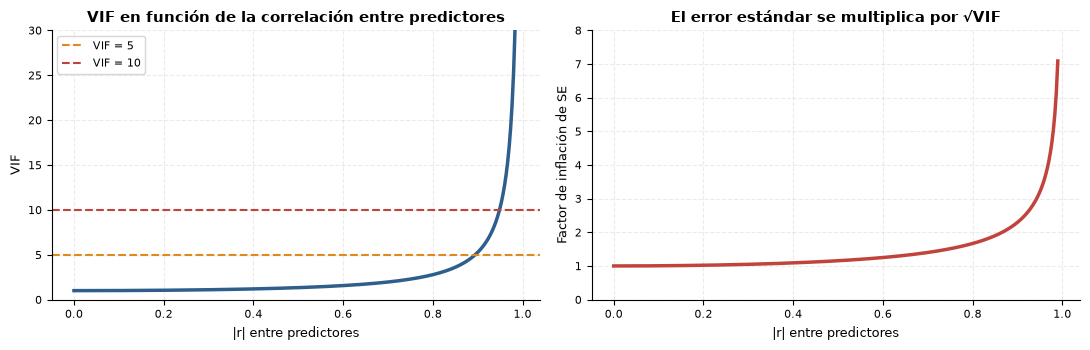

|r| entre predictores,VIF,SE se multiplica por,n necesario para igual precisión
0.000000,1.0,1.00×,1× más
0.500000,1.3,1.15×,1× más
0.800000,2.8,1.67×,3× más
0.900000,5.3,2.29×,5× más
0.950000,10.3,3.20×,10× más
0.990000,50.3,7.09×,50× más



Tres consecuencias, y ninguna es que el modelo esté "mal":
  · β̂ sigue siendo INSESGADO. La colinealidad no distorsiona la estimación.
  · Su error estándar se multiplica por √VIF -> pierdes potencia para detectar el efecto.
    Con r = 0.95 necesitarías ~10 veces más datos para la misma precisión.
  · La PREDICCIÓN no se ve afectada en absoluto.

Por eso su prioridad depende del objetivo: es 🟢 tolerable si solo predices y 🟡 corregible
si necesitas interpretar coeficientes individuales.



In [15]:
# Relación exacta entre colinealidad e imprecisión (analítica, sin simulación)
# ==============================================================================
r_grid = np.linspace(0, 0.99, 300)
vif_grid = 1 / (1 - r_grid ** 2)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(r_grid, vif_grid, color=AZUL, lw=2.5)
for umbral, c in [(5, NARANJA), (10, ROJO)]:
    ax[0].axhline(umbral, color=c, ls='--', lw=1.5, label=f'VIF = {umbral}')
ax[0].set(title='VIF en función de la correlación entre predictores', xlabel='|r| entre predictores',
          ylabel='VIF', ylim=(0, 30)); ax[0].legend()

ax[1].plot(r_grid, np.sqrt(vif_grid), color=ROJO, lw=2.5)
ax[1].set(title='El error estándar se multiplica por √VIF', xlabel='|r| entre predictores',
          ylabel='Factor de inflación de SE', ylim=(0, 8))

plt.tight_layout(); plt.show()

tabla_col = pd.DataFrame({'|r| entre predictores': [0, .5, .8, .9, .95, .99]})
tabla_col['VIF'] = 1 / (1 - tabla_col['|r| entre predictores'] ** 2)
tabla_col['SE se multiplica por'] = np.sqrt(tabla_col.VIF)
tabla_col['n necesario para igual precisión'] = tabla_col.VIF
display(tabla_col.style.format({'VIF': '{:.1f}', 'SE se multiplica por': '{:.2f}×',
                                'n necesario para igual precisión': '{:.0f}× más'}).hide(axis='index'))

print("""
Tres consecuencias, y ninguna es que el modelo esté "mal":
  · β̂ sigue siendo INSESGADO. La colinealidad no distorsiona la estimación.
  · Su error estándar se multiplica por √VIF -> pierdes potencia para detectar el efecto.
    Con r = 0.95 necesitarías ~10 veces más datos para la misma precisión.
  · La PREDICCIÓN no se ve afectada en absoluto.

Por eso su prioridad depende del objetivo: es 🟢 tolerable si solo predices y 🟡 corregible
si necesitas interpretar coeficientes individuales.
""")

---

## 6. Comparación de modelos anidados: el test F parcial

`periodico` no es significativo. Antes de eliminarlo, formalicemos la decisión comparando el
modelo completo $M$ con el reducido $m$ (anidado en él):

$$F = \frac{(SSE_m - SSE_M)/(gl_m - gl_M)}{SSE_M/gl_M} \;\sim\; F_{(gl_m-gl_M),\;gl_M}$$

**H₀:** los coeficientes de los predictores excluidos son todos nulos.

El numerador mide cuánto empeora el ajuste al quitar variables, por variable quitada; el
denominador, la variabilidad residual del modelo grande. Si quitar la variable no empeora nada,
$F \approx 0$ y nos quedamos con el modelo pequeño por **parsimonia**.

In [16]:
# Modelo B (reducido) y test F parcial
# ==============================================================================
modelo_B = smf.ols('ventas ~ tv + radio', data=train).fit()
print(modelo_B.summary().tables[0])
print(modelo_B.summary().tables[1])

print("\nTest F parcial (H0: β_periodico = 0):")
display(anova_lm(modelo_B, modelo_A))

t_per = modelo_A.tvalues['periodico']
f_par = anova_lm(modelo_B, modelo_A)['F'].iloc[1]
print(f"\nEquivalencia t² = F cuando se contrasta UNA sola restricción:")
print(f"   t(periodico)² = {t_per:.6f}² = {t_per**2:.6f}")
print(f"   F parcial     = {f_par:.6f}")

                            OLS Regression Results                            
Dep. Variable:                 ventas   R-squared:                       0.894
Model:                            OLS   Adj. R-squared:                  0.892
Method:                 Least Squares   F-statistic:                     660.3
Date:                Tue, 04 Aug 2026   Prob (F-statistic):           3.69e-77
Time:                        19:35:17   Log-Likelihood:                -308.36
No. Observations:                 160   AIC:                             622.7
Df Residuals:                     157   BIC:                             631.9
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      2.9004      0.335      8.652      0.0

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,157.0000,442.2127,0.0000,NaN,NaN,NaN
1,156.0000,441.8550,1.0000,0.3577,0.1263,0.7228



Equivalencia t² = F cuando se contrasta UNA sola restricción:
   t(periodico)² = 0.355395² = 0.126306
   F parcial     = 0.126306


In [17]:
# Criterios de información: otra vía para comparar
# ==============================================================================
comp_AB = pd.DataFrame({
    'modelo'     : ['A: tv + radio + periodico', 'B: tv + radio'],
    'k'          : [int(modelo_A.df_model), int(modelo_B.df_model)],
    'R²'         : [modelo_A.rsquared, modelo_B.rsquared],
    'R² ajustado': [modelo_A.rsquared_adj, modelo_B.rsquared_adj],
    'AIC'        : [modelo_A.aic, modelo_B.aic],
    'BIC'        : [modelo_A.bic, modelo_B.bic],
    'log-verosim.': [modelo_A.llf, modelo_B.llf],
})
display(comp_AB.style.format({'R²': '{:.4f}', 'R² ajustado': '{:.4f}', 'AIC': '{:.1f}',
                              'BIC': '{:.1f}', 'log-verosim.': '{:.1f}'}).hide(axis='index'))

print('''
Los tres criterios apuntan en la misma dirección:
  · R² prácticamente idéntico (0.8938 vs 0.8937): 'periodico' aporta ~0.01% de varianza explicada.
  · R² AJUSTADO mayor en el modelo reducido: la penalización por parámetro supera su aporte.
  · AIC y BIC menores en el modelo reducido (menor = mejor).
  · Test F parcial: p = 0.723, no se rechaza H0.

DECISIÓN: nos quedamos con el modelo B (tv + radio).
''')

modelo,k,R²,R² ajustado,AIC,BIC,log-verosim.
A: tv + radio + periodico,3,0.8938,0.8918,624.6,636.9,-308.3
B: tv + radio,2,0.8937,0.8924,622.7,631.9,-308.4



Los tres criterios apuntan en la misma dirección:
  · R² prácticamente idéntico (0.8938 vs 0.8937): 'periodico' aporta ~0.01% de varianza explicada.
  · R² AJUSTADO mayor en el modelo reducido: la penalización por parámetro supera su aporte.
  · AIC y BIC menores en el modelo reducido (menor = mejor).
  · Test F parcial: p = 0.723, no se rechaza H0.

DECISIÓN: nos quedamos con el modelo B (tv + radio).



### Nota metodológica: AIC, BIC y el peligro de la selección automática

$$\text{AIC} = -2\ln \hat L + 2p, \qquad \text{BIC} = -2\ln\hat L + p\ln n$$

Ambos penalizan la complejidad, pero con filosofías distintas:

| | AIC | BIC |
|---|---|---|
| Penalización | $2p$ | $p\ln n$ (más dura si $n > 7$) |
| Objetivo | Minimizar el error de predicción | Identificar el modelo "verdadero" |
| Tendencia | Selecciona modelos más grandes | Selecciona modelos más parsimoniosos |
| Consistencia | No consistente | Consistente (si el modelo verdadero está entre los candidatos) |

> ⚠️ **Inferencia post-selección.** Si eliges variables mirando los p-valores y después reportas
> los p-valores del modelo final **como si el modelo hubiera sido especificado de antemano**, esos
> p-valores están sesgados a la baja: has hecho una búsqueda y no la has descontado. Es el mismo
> problema del *stepwise* automático, que además es inestable (pequeños cambios en los datos
> producen modelos distintos) y capitaliza el ruido.
>
> Prácticas defendibles: especificar el modelo a partir del conocimiento del dominio, validar la
> selección por validación cruzada, usar regularización (LASSO), o reservar una muestra
> independiente para la inferencia final. En esta clase eliminamos `periodico` con criterio
> sustantivo (no hay mecanismo causal plausible una vez controlada la radio) *y* estadístico, y
> validaremos todo fuera de muestra.

---

## 7. Diagnóstico del modelo B: cuando todo falla a la vez

Tenemos un modelo con $R^2 = 0.894$, un $F$ enorme y dos predictores altamente significativos.
Cualquiera lo daría por bueno. **Vamos a auditarlo.**

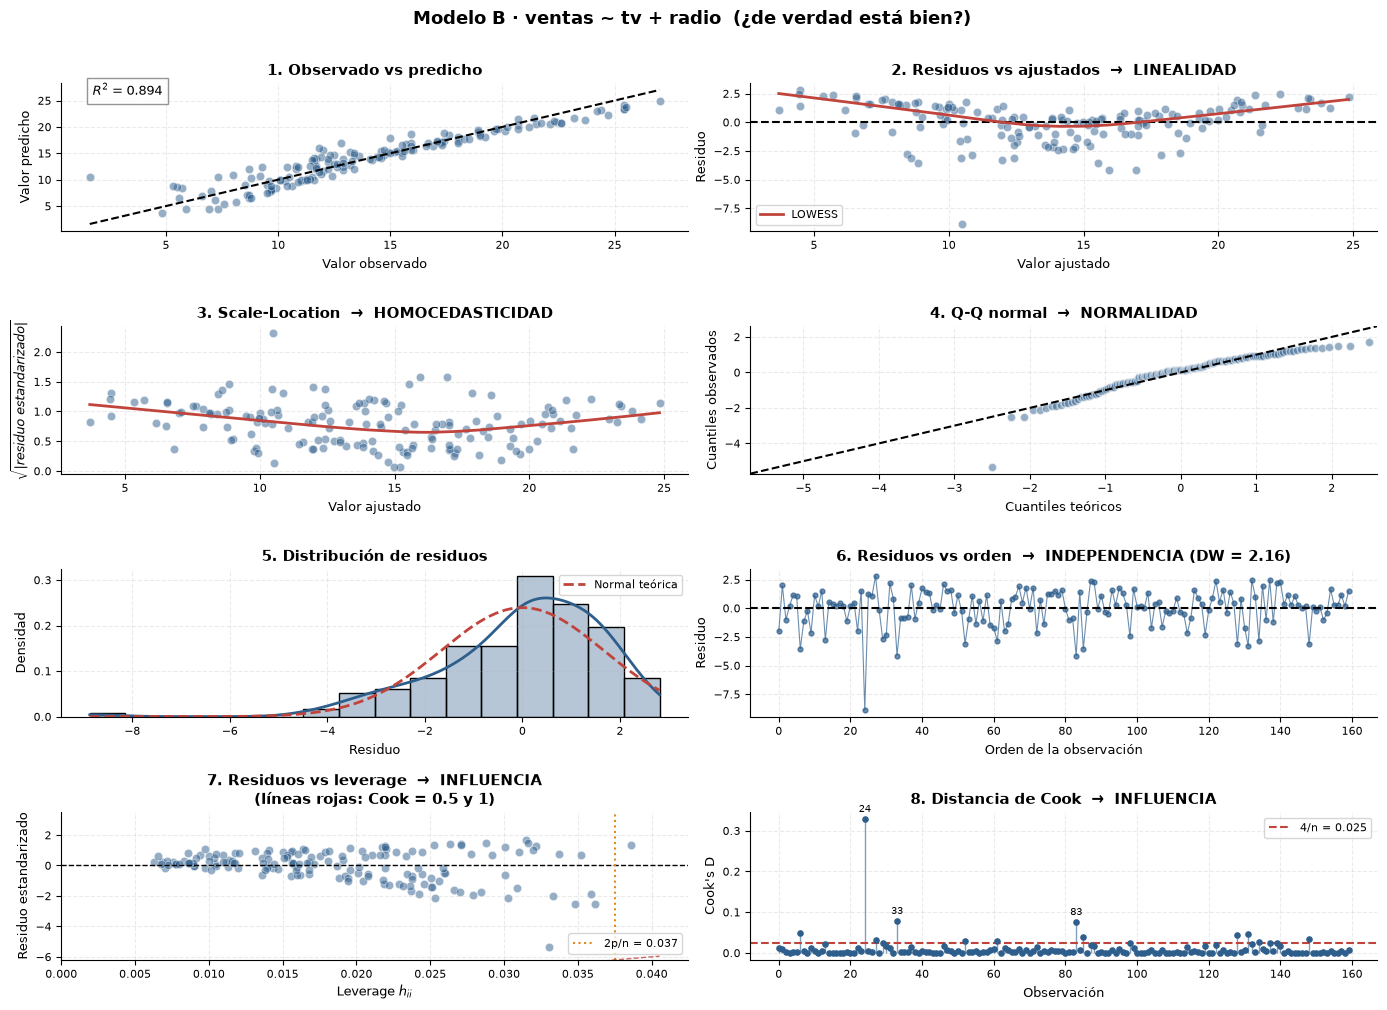

In [18]:
panel_diagnostico(modelo_B, titulo='Modelo B · ventas ~ tv + radio  (¿de verdad está bien?)')

In [19]:
diagnostico(modelo_B, objetivo='inferencia', orden_con_sentido=False)

OBJETIVO: INFERENCIA   ·   n = 160   ·   k = 2
VEREDICTO: ⛔ NO PROCEDE tal cual — 1 problema(s) BLOQUEANTE(S).
           Corregir la especificación y volver a diagnosticar. Los coeficientes
           actuales están sesgados: no tiene sentido interpretarlos ni corregir
           los errores estándar todavía.


Supuesto,Chequeo,Resultado,¿Se cumple?,Prioridad,Qué hacer
A1 · Linealidad,RESET de Ramsey,p = 1.55e-11,✘,🔴 BLOQUEANTE,Transformar / añadir interacción ANTES de leer ningún coeficiente
A2 · Exogeneidad,NO hay test estadístico,requiere criterio del dominio,—,🟡 limita la lectura,Solo diseño experimental o variables instrumentales lo garantizan
A3 · Homocedasticidad,White,p = 1.9e-09,✘,🟡 corregible,Usar errores estándar robustos HC3 (una línea de código)
A4 · Independencia,Durbin-Watson,DW = 2.16,—,⚪ no aplicable,Sin orden natural (tiempo/espacio) el test no es interpretable
A5 · Normalidad,Jarque-Bera,p ≈ 0,✘,🟢 tolerable,Con n = 160 el TLC protege los tests t y F
A6 · Colinealidad,VIF máximo,tv: 1.0,✔,🟢 correcto,Seguir
Influencia,Cook's D,máx = 0.33 · 12 obs > 4/n,✘,🟡 revisar,Análisis de sensibilidad: reajustar sin ellas y comparar conclusiones


### El diagnóstico habla claro

| Supuesto | Resultado | Evidencia |
|---|---|---|
| **A1 Linealidad** | ❌ **VIOLADO** | RESET $p \approx 1.5\times10^{-11}$. El panel 2 muestra una **curva en ∩** inequívoca. |
| **A3 Homocedasticidad** | ❌ **VIOLADO** | White $p \approx 1.9\times10^{-9}$ (Breusch-Pagan no lo detecta: $p = 0.195$). |
| **A5 Normalidad** | ❌ **VIOLADO** | Shapiro $p \approx 6\times10^{-8}$, asimetría $-1.38$, curtosis $7.0$. |
| Influencia | ⚠️ | 12 observaciones con $D_i > 4/n$. |

#### ¿Por qué Breusch-Pagan dice que no y White dice que sí?

No es una contradicción, es **información**:

- **Breusch-Pagan** regresa $e_i^2$ sobre `tv` y `radio` (forma lineal). Aquí la varianza **no**
  crece linealmente con los predictores, así que BP no ve nada.
- **White** añade cuadrados y productos cruzados. La heterocedasticidad real tiene forma
  cuadrática/multiplicativa, y por eso White la detecta con contundencia.

**Regla práctica:** si BP y White discrepan, la heterocedasticidad no es lineal en los predictores;
confía en White (o mira el gráfico Scale-Location, que aquí es concluyente).

#### La observación crucial: los tres fallos tienen **una sola causa**

Es tentador tratar cada violación por separado: transformar $Y$ para arreglar la normalidad, usar
WLS para la heterocedasticidad... Sería un error. Mira el panel 2 del diagnóstico:

- Los residuos son **positivos en los extremos y negativos en el centro** → forma de ∩.
- Es decir: el modelo **infraestima** las ventas en regiones de presupuesto muy bajo y muy alto, y
  las **sobreestima** en el rango medio.

Cuando un modelo comete errores *sistemáticos* (no aleatorios), esos errores se acumulan en la
distribución residual y producen asimetría (no normalidad) y varianza no constante
(heterocedasticidad).

> 🎯 **Principio de diagnóstico:** *primero la especificación, después la inferencia.*
> La no-normalidad y la heterocedasticidad son con frecuencia **síntomas** de un modelo mal
> especificado, no enfermedades independientes. Corregir los síntomas (errores robustos,
> transformar $Y$) sin corregir la causa (falta un término en el modelo) deja intacto el problema
> grave: **A1 violado sesga los coeficientes**.

Vamos a buscar qué falta.

In [20]:
# ¿Por qué el diagnóstico mínimo usa White y no Breusch-Pagan?
# ==============================================================================
bp = het_breuschpagan(modelo_B.resid, modelo_B.model.exog)
wh = het_white(modelo_B.resid, modelo_B.model.exog)

print(f"Breusch-Pagan : LM = {bp[0]:7.3f}   p = {bp[1]:.3g}   -> NO detecta heterocedasticidad")
print(f"White         : LM = {wh[0]:7.3f}   p = {wh[3]:.3g}   -> SÍ la detecta, con contundencia")
print("""
No es una contradicción: es información sobre la FORMA del problema.
  · Breusch-Pagan regresa e² sobre los predictores tal cual -> solo ve heterocedasticidad LINEAL.
  · White añade cuadrados y productos cruzados             -> ve también formas no lineales.

Aquí la varianza no crece linealmente con tv ni con radio, por eso BP no ve nada.

Criterio práctico: usar White por defecto (es el más general). Si BP y White discrepan,
la heterocedasticidad no es lineal en los predictores. Y por encima de los dos manda el
gráfico Scale-Location, que aquí es concluyente.
""")

Breusch-Pagan : LM =   3.298   p = 0.192   -> NO detecta heterocedasticidad
White         : LM =  43.509   p = 1.9e-09   -> SÍ la detecta, con contundencia

No es una contradicción: es información sobre la FORMA del problema.
  · Breusch-Pagan regresa e² sobre los predictores tal cual -> solo ve heterocedasticidad LINEAL.
  · White añade cuadrados y productos cruzados             -> ve también formas no lineales.

Aquí la varianza no crece linealmente con tv ni con radio, por eso BP no ve nada.

Criterio práctico: usar White por defecto (es el más general). Si BP y White discrepan,
la heterocedasticidad no es lineal en los predictores. Y por encima de los dos manda el
gráfico Scale-Location, que aquí es concluyente.



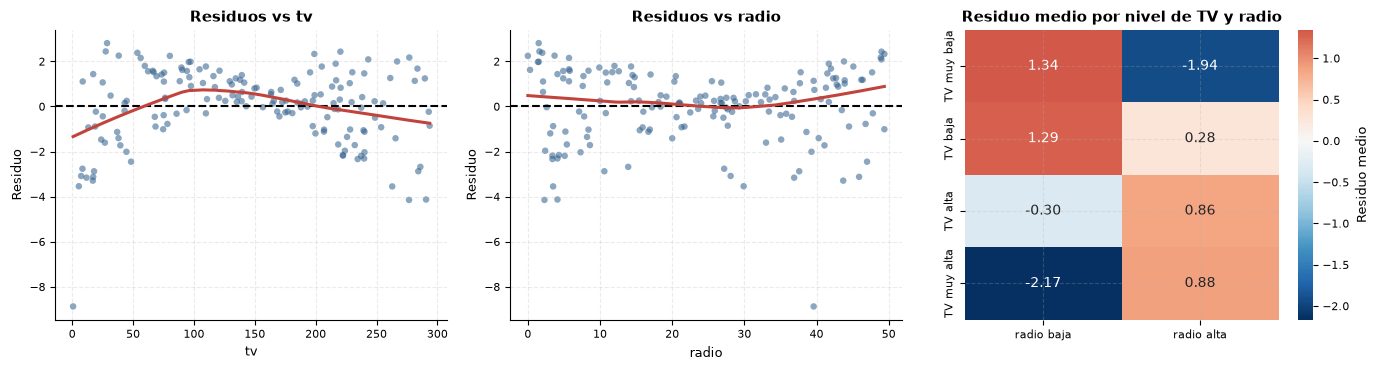


El mapa de calor es la pista definitiva. Los residuos medios forman un patrón EN DIAGONAL:

  · TV muy alta + radio alta  -> residuo POSITIVO  (+0.88): el modelo INFRAESTIMA
  · TV muy baja + radio baja  -> residuo POSITIVO  (+1.34): el modelo INFRAESTIMA
  · TV muy alta + radio baja  -> residuo NEGATIVO  (-2.17): el modelo SOBREESTIMA
  · TV muy baja + radio alta  -> residuo NEGATIVO  (-1.94): el modelo SOBREESTIMA

Es decir: el modelo se equivoca en un sentido cuando ambos canales van EN LA MISMA DIRECCIÓN
y en el sentido contrario cuando van en direcciones OPUESTAS. Ese patrón diagonal es la firma
exacta de un término PRODUCTO omitido: el efecto de la TV depende del nivel de radio.
Un modelo aditivo no puede reproducir esa estructura por construcción.



In [21]:
# ¿Dónde falla exactamente el modelo? Residuos frente a cada predictor
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, var in zip(axes, ['tv', 'radio']):
    ax.scatter(train[var], modelo_B.resid, s=22, alpha=.55, color=AZUL, edgecolors='none')
    ax.axhline(0, color='black', ls='--', lw=1.5)
    sl = sm.nonparametric.lowess(modelo_B.resid, train[var], frac=.6)
    ax.plot(sl[:, 0], sl[:, 1], color=ROJO, lw=2.2)
    ax.set(title=f'Residuos vs {var}', xlabel=var, ylabel='Residuo')

# Residuo medio según el nivel conjunto de tv y radio
train_aux = train.assign(resid=modelo_B.resid,
                         tv_grupo=pd.qcut(train.tv, 4, labels=['TV muy baja', 'TV baja', 'TV alta', 'TV muy alta']),
                         radio_grupo=pd.qcut(train.radio, 2, labels=['radio baja', 'radio alta']))
tabla_calor = train_aux.pivot_table(index='tv_grupo', columns='radio_grupo', values='resid',
                                    aggfunc='mean', observed=True)
sns.heatmap(tabla_calor, annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=axes[2],
            cbar_kws={'label': 'Residuo medio'})
axes[2].set(title='Residuo medio por nivel de TV y radio', xlabel='', ylabel='')
plt.tight_layout(); plt.show()

print('''
El mapa de calor es la pista definitiva. Los residuos medios forman un patrón EN DIAGONAL:

  · TV muy alta + radio alta  -> residuo POSITIVO  (+0.88): el modelo INFRAESTIMA
  · TV muy baja + radio baja  -> residuo POSITIVO  (+1.34): el modelo INFRAESTIMA
  · TV muy alta + radio baja  -> residuo NEGATIVO  (-2.17): el modelo SOBREESTIMA
  · TV muy baja + radio alta  -> residuo NEGATIVO  (-1.94): el modelo SOBREESTIMA

Es decir: el modelo se equivoca en un sentido cuando ambos canales van EN LA MISMA DIRECCIÓN
y en el sentido contrario cuando van en direcciones OPUESTAS. Ese patrón diagonal es la firma
exacta de un término PRODUCTO omitido: el efecto de la TV depende del nivel de radio.
Un modelo aditivo no puede reproducir esa estructura por construcción.
''')

---

## 8. Modelo C: interacción entre predictores

### El concepto

El modelo aditivo asume que el efecto de la TV sobre las ventas es el mismo tanto si no se invierte
nada en radio como si se invierte el máximo:

$$Y = \beta_0 + \beta_1 X_1 + \beta_2 X_2 + \varepsilon
\qquad\Longrightarrow\qquad \frac{\partial Y}{\partial X_1} = \beta_1 \;\;(\text{constante})$$

En marketing esto es sustantivamente implausible: los canales se **potencian** entre sí (una
campaña de radio hace más efectivos los anuncios de TV, y viceversa: *efecto sinergia*). Para
permitirlo se añade un término producto:

$$Y = \beta_0 + \beta_1 X_1 + \beta_2 X_2 + \beta_3 X_1 X_2 + \varepsilon$$

y reorganizando:

$$Y = \beta_0 + \underbrace{(\beta_1 + \beta_3 X_2)}_{\text{efecto de } X_1,\ \text{ahora depende de } X_2} X_1 + \beta_2 X_2 + \varepsilon$$

$$\frac{\partial Y}{\partial X_1} = \beta_1 + \beta_3 X_2 \qquad
\frac{\partial Y}{\partial X_2} = \beta_2 + \beta_3 X_1$$

**El efecto marginal ya no es un número, es una función.**

### Dos reglas de oro con interacciones

1. **Principio de jerarquía** (*hierarchical principle*): si incluyes $X_1X_2$, debes incluir
   $X_1$ y $X_2$ por separado **aunque no sean significativos**. Si no, estás imponiendo una
   restricción arbitraria al modelo que además lo hace dependiente del origen de las escalas.
2. **Los coeficientes de los términos principales cambian de significado.** Con interacción,
   $\beta_1$ ya **no** es "el efecto de $X_1$": es el efecto de $X_1$ **cuando $X_2 = 0$**. Si el
   valor 0 no es plausible en los datos, ese coeficiente puede carecer de interpretación
   sustantiva —y su p-valor con él—.

En la sintaxis de fórmula: `tv * radio` es equivalente a `tv + radio + tv:radio`.

In [22]:
modelo_C = smf.ols('ventas ~ tv * radio', data=train).fit()
print(modelo_C.summary().tables[0])
print(modelo_C.summary().tables[1])

print("\nTest F parcial (H0: β_interacción = 0) — modelo B vs modelo C:")
display(anova_lm(modelo_B, modelo_C))

                            OLS Regression Results                            
Dep. Variable:                 ventas   R-squared:                       0.968
Model:                            OLS   Adj. R-squared:                  0.967
Method:                 Least Squares   F-statistic:                     1562.
Date:                Tue, 04 Aug 2026   Prob (F-statistic):          4.28e-116
Time:                        19:35:18   Log-Likelihood:                -212.91
No. Observations:                 160   AIC:                             433.8
Df Residuals:                     156   BIC:                             446.1
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      6.9035      0.281     24.558      0.0

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,157.0000,442.2127,0.0000,NaN,NaN,NaN
1,156.0000,134.1166,1.0000,308.0961,358.3673,0.0000


### Interpretación del modelo C

$$\widehat{\text{ventas}} = 6.904 + 0.0183\,\text{tv} + 0.0261\,\text{radio} + 0.00111\,(\text{tv}\times\text{radio})$$

- La interacción es **fuertemente significativa**: $t = 18.9$, $p \approx 3\times10^{-42}$, y el
  test F parcial da $F = 358.4$.
- $R^2$ sube de 0.894 a **0.968**, y el $R^2$ ajustado de 0.892 a 0.967.
- **Efecto marginal de la TV** $= 0.0183 + 0.00111\times\text{radio}$:
  - con `radio = 0`: cada millón en TV aporta 0.018 de ventas,
  - con `radio = 25`: aporta 0.046,
  - con `radio = 49` (máximo): aporta 0.073, **cuatro veces más**.
- Lectura de negocio: **la publicidad en TV y en radio se potencian**. El presupuesto no debe
  asignarse canal por canal de forma independiente.

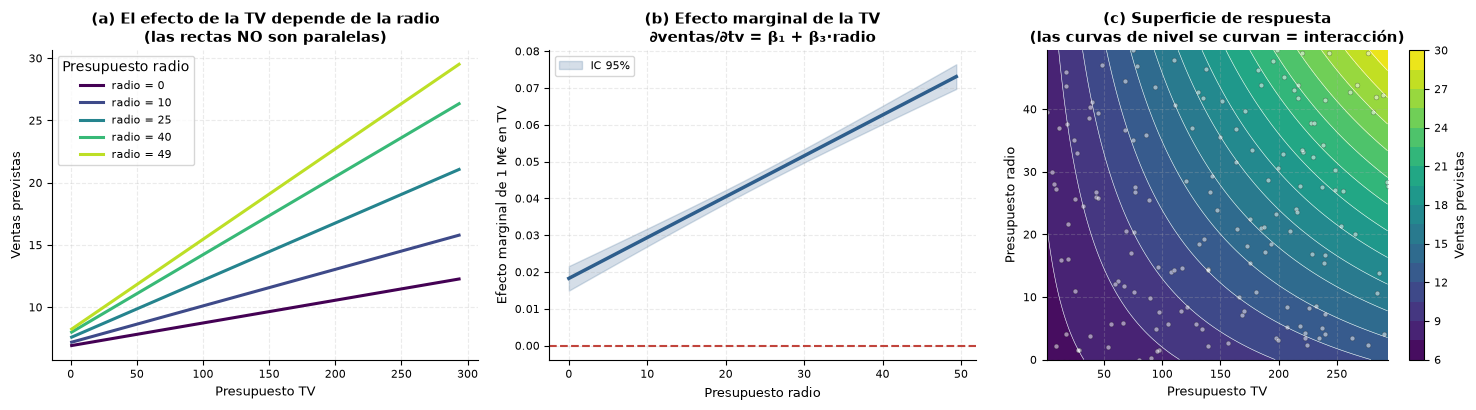

In [23]:
# Visualización de la interacción
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

# (a) rectas de ventas vs tv para distintos niveles de radio
niveles = [0, 10, 25, 40, 49]
tv_grid = np.linspace(train.tv.min(), train.tv.max(), 60)
cmap = plt.cm.viridis(np.linspace(0, .9, len(niveles)))
for c, rad in zip(cmap, niveles):
    pred = modelo_C.predict(pd.DataFrame({'tv': tv_grid, 'radio': rad}))
    axes[0].plot(tv_grid, pred, color=c, lw=2.2, label=f'radio = {rad}')
axes[0].legend(title='Presupuesto radio')
axes[0].set(title='(a) El efecto de la TV depende de la radio\n(las rectas NO son paralelas)',
            xlabel='Presupuesto TV', ylabel='Ventas previstas')

# (b) efecto marginal de tv en función de radio, con banda de confianza
radio_grid = np.linspace(0, train.radio.max(), 60)
b_tv, b_int = modelo_C.params['tv'], modelo_C.params['tv:radio']
cov = modelo_C.cov_params()
var_me = (cov.loc['tv', 'tv'] + radio_grid**2 * cov.loc['tv:radio', 'tv:radio']
          + 2 * radio_grid * cov.loc['tv', 'tv:radio'])
me   = b_tv + b_int * radio_grid
tcrit = stats.t.ppf(.975, modelo_C.df_resid)
axes[1].plot(radio_grid, me, color=AZUL, lw=2.5)
axes[1].fill_between(radio_grid, me - tcrit*np.sqrt(var_me), me + tcrit*np.sqrt(var_me),
                     color=AZUL, alpha=.2, label='IC 95%')
axes[1].axhline(0, color=ROJO, ls='--', lw=1.5)
axes[1].legend()
axes[1].set(title='(b) Efecto marginal de la TV\n∂ventas/∂tv = β₁ + β₃·radio',
            xlabel='Presupuesto radio', ylabel='Efecto marginal de 1 M€ en TV')

# (c) superficie de respuesta
tv_m, radio_m = np.meshgrid(np.linspace(train.tv.min(), train.tv.max(), 60),
                            np.linspace(train.radio.min(), train.radio.max(), 60))
Z = modelo_C.predict(pd.DataFrame({'tv': tv_m.ravel(), 'radio': radio_m.ravel()})).values.reshape(tv_m.shape)
cf = axes[2].contourf(tv_m, radio_m, Z, levels=18, cmap='viridis')
axes[2].contour(tv_m, radio_m, Z, levels=18, colors='white', linewidths=.4)
axes[2].scatter(train.tv, train.radio, s=12, color='white', alpha=.5, edgecolors='black', lw=.3)
plt.colorbar(cf, ax=axes[2], label='Ventas previstas')
axes[2].set(title='(c) Superficie de respuesta\n(las curvas de nivel se curvan = interacción)',
            xlabel='Presupuesto TV', ylabel='Presupuesto radio')
plt.tight_layout(); plt.show()

### 🔍 Ampliación · Colinealidad estructural en los términos de interacción

Al añadir `tv:radio` aparece un fenómeno predecible: el producto está fuertemente correlacionado
con sus factores, y los VIF se disparan. Es **colinealidad estructural** —creada por nosotros al
construir el término, no presente en los datos— y se elimina **centrando** los predictores.

In [24]:
# Colinealidad estructural y su solución: centrar
# ==============================================================================
train_c  = train.assign(tv_c=train.tv - train.tv.mean(),
                        radio_c=train.radio - train.radio.mean())
modelo_Cc = smf.ols('ventas ~ tv_c * radio_c', data=train_c).fit()

comp_vif = pd.concat([
    tabla_vif(modelo_C).assign(version='sin centrar')[['version', 'variable', 'VIF']],
    tabla_vif(modelo_Cc).assign(version='centrado')[['version', 'variable', 'VIF']],
])
display(comp_vif.style.format({'VIF': '{:.2f}'}).hide(axis='index'))

print(f"Número de condición  ·  sin centrar: {modelo_C.condition_number:>10,.0f}"
      f"   ·  centrado: {modelo_Cc.condition_number:>10,.0f}")
print(f"R²                   ·  sin centrar: {modelo_C.rsquared:.6f}   ·  centrado: {modelo_Cc.rsquared:.6f}")
print(f"Coef. de interacción ·  sin centrar: {modelo_C.params['tv:radio']:.6f}"
      f"   ·  centrado: {modelo_Cc.params['tv_c:radio_c']:.6f}")
print('''
Centrar NO cambia el ajuste ni el coeficiente de la interacción: cambia el punto de referencia.
  · Sin centrar, β(tv) es el efecto de la TV cuando radio = 0 (un escenario poco realista).
  · Centrado,   β(tv_c) es el efecto de la TV para una región con radio PROMEDIO (interpretable).
Es la solución estándar para la colinealidad estructural de los términos de interacción y
polinómicos.
''')

version,variable,VIF
sin centrar,Intercept,14.71
sin centrar,tv,3.72
sin centrar,radio,4.13
sin centrar,tv:radio,7.01
centrado,Intercept,1.00
centrado,tv_c,1.01
centrado,radio_c,1.00
centrado,tv_c:radio_c,1.01


Número de condición  ·  sin centrar:     18,421   ·  centrado:      1,255
R²                   ·  sin centrar: 0.967776   ·  centrado: 0.967776
Coef. de interacción ·  sin centrar: 0.001110   ·  centrado: 0.001110

Centrar NO cambia el ajuste ni el coeficiente de la interacción: cambia el punto de referencia.
  · Sin centrar, β(tv) es el efecto de la TV cuando radio = 0 (un escenario poco realista).
  · Centrado,   β(tv_c) es el efecto de la TV para una región con radio PROMEDIO (interpretable).
Es la solución estándar para la colinealidad estructural de los términos de interacción y
polinómicos.



## 9. ¿Está ya bien el modelo C? Re-diagnóstico

Hemos pasado de $R^2 = 0.894$ a $R^2 = 0.968$ y la interacción es abrumadoramente significativa.
La tentación es parar aquí. **Volvamos a diagnosticar.**

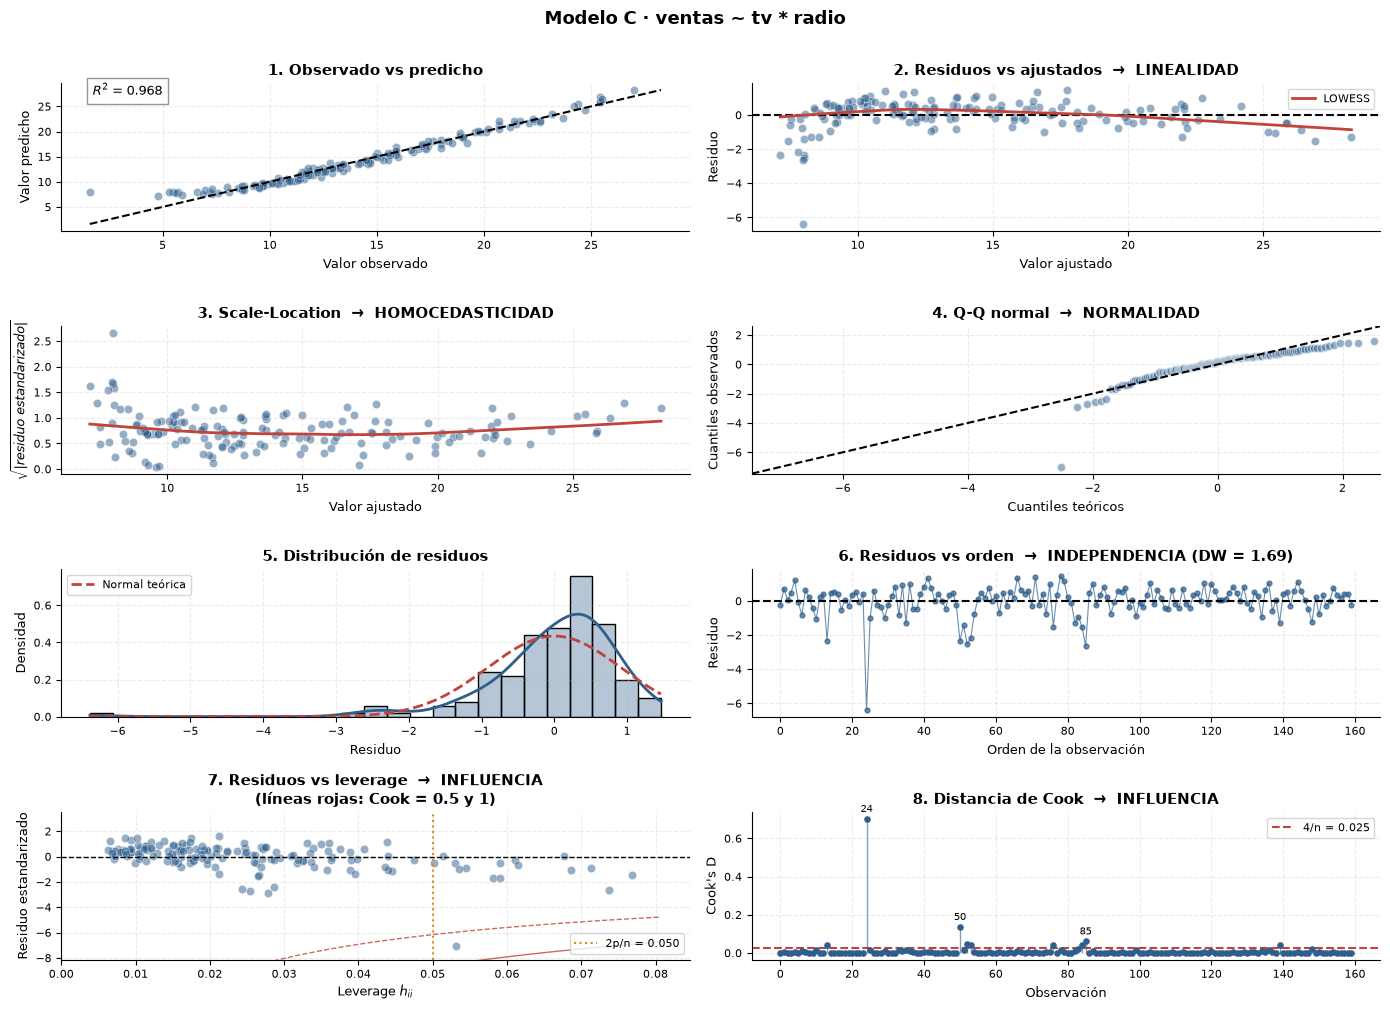

In [25]:
panel_diagnostico(modelo_C, titulo='Modelo C · ventas ~ tv * radio')

In [26]:
diagnostico(modelo_C, objetivo='inferencia', orden_con_sentido=False)

OBJETIVO: INFERENCIA   ·   n = 160   ·   k = 3
VEREDICTO: ⛔ NO PROCEDE tal cual — 1 problema(s) BLOQUEANTE(S).
           Corregir la especificación y volver a diagnosticar. Los coeficientes
           actuales están sesgados: no tiene sentido interpretarlos ni corregir
           los errores estándar todavía.


Supuesto,Chequeo,Resultado,¿Se cumple?,Prioridad,Qué hacer
A1 · Linealidad,RESET de Ramsey,p = 1.33e-14,✘,🔴 BLOQUEANTE,Transformar / añadir interacción ANTES de leer ningún coeficiente
A2 · Exogeneidad,NO hay test estadístico,requiere criterio del dominio,—,🟡 limita la lectura,Solo diseño experimental o variables instrumentales lo garantizan
A3 · Homocedasticidad,White,p = 0.000452,✘,🟡 corregible,Usar errores estándar robustos HC3 (una línea de código)
A4 · Independencia,Durbin-Watson,DW = 1.69,—,⚪ no aplicable,Sin orden natural (tiempo/espacio) el test no es interpretable
A5 · Normalidad,Jarque-Bera,p ≈ 0,✘,🟢 tolerable,Con n = 160 el TLC protege los tests t y F
A6 · Colinealidad,VIF máximo,tv:radio: 7.0,✔,🟢 correcto,Seguir
Influencia,Cook's D,máx = 0.70 · 9 obs > 4/n,✘,🟡 revisar,Análisis de sensibilidad: reajustar sin ellas y comparar conclusiones


### Mejoró, pero sigue mal especificado

- **RESET $p \approx 1.3\times10^{-14}$**: sigue faltando estructura. El panel 2 muestra ahora una
  curvatura distinta, con un grupo de residuos muy negativos a la izquierda.
- La normalidad **empeoró** (asimetría $-2.64$, curtosis $16.9$): unas pocas observaciones con
  presupuestos muy bajos son predichas terriblemente mal.
- La heterocedasticidad persiste (White $p = 4.5\times10^{-4}$).

Añadir la interacción resolvió *una* mala especificación, pero destapó otra. Volvamos al gráfico
`ventas ~ tv`: la relación **no es lineal, se satura**. Cada millón adicional en TV rinde menos que
el anterior: **rendimientos marginales decrecientes**, un fenómeno económico esperable.

Un modelo lineal en `tv` no puede reproducir eso. Necesitamos una transformación cóncava.

## 10. Modelo D: transformación de la escala del predictor

### ¿Qué transformación?

| Transformación | Forma | Cuándo usarla | Interpretación de $\beta$ |
|---|---|---|---|
| $\sqrt{X}$ | Cóncava suave | Saturación moderada; admite $X = 0$ | Efecto por unidad de $\sqrt X$ |
| $\ln(X)$ | Cóncava fuerte | Efectos multiplicativos; **requiere $X>0$** | Cambio en $Y$ por cada 1% de cambio en $X$ (÷100) |
| $\ln(Y)$ | — | Varianza proporcional al nivel; efectos multiplicativos | Cambio **porcentual** de $Y$ |
| $X^2$ | Convexa/parabólica | Efectos con máximo o mínimo interior | Con $X$: forma de U o ∩ |
| Box-Cox | $\frac{Y^\lambda-1}{\lambda}$ | Elección **guiada por los datos** de cómo transformar $Y$ | $\lambda=1$: nada; $\lambda=0.5$: raíz; $\lambda=0$: log |

La transformación de **Box-Cox** estima $\lambda$ por máxima verosimilitud, de forma que el
resultado sea lo más normal posible. Lo aplicamos como diagnóstico orientativo.

λ de Box-Cox estimado para 'ventas': 0.5980  (λ=1 → sin transformar, λ=0.5 → raíz cuadrada, λ=0 → logaritmo)


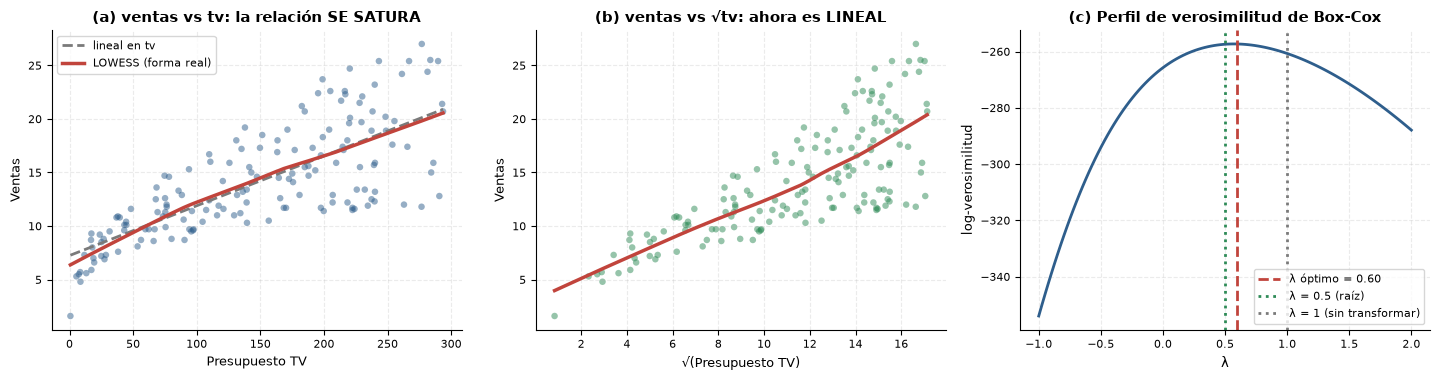

In [27]:
# ¿Qué forma funcional piden los datos?
# ==============================================================================
lam_bc = stats.boxcox_normmax(train.ventas.values)
print(f"λ de Box-Cox estimado para 'ventas': {lam_bc:.4f}  (λ=1 → sin transformar, "
      f"λ=0.5 → raíz cuadrada, λ=0 → logaritmo)")

fig, ax = plt.subplots(1, 3, figsize=(14.5, 3.9))

# (a) relación cruda ventas ~ tv con ajuste lineal y con raíz
ax[0].scatter(train.tv, train.ventas, s=22, alpha=.5, color=AZUL, edgecolors='none')
tvg = np.linspace(train.tv.min(), train.tv.max(), 100)
lin = np.polyfit(train.tv, train.ventas, 1)
ax[0].plot(tvg, np.polyval(lin, tvg), color=GRIS, ls='--', lw=2, label='lineal en tv')
sl = sm.nonparametric.lowess(train.ventas, train.tv, frac=.6)
ax[0].plot(sl[:, 0], sl[:, 1], color=ROJO, lw=2.5, label='LOWESS (forma real)')
ax[0].legend(); ax[0].set(title='(a) ventas vs tv: la relación SE SATURA',
                          xlabel='Presupuesto TV', ylabel='Ventas')

# (b) tras aplicar la raíz cuadrada
ax[1].scatter(np.sqrt(train.tv), train.ventas, s=22, alpha=.5, color=VERDE, edgecolors='none')
sl2 = sm.nonparametric.lowess(train.ventas, np.sqrt(train.tv), frac=.6)
ax[1].plot(sl2[:, 0], sl2[:, 1], color=ROJO, lw=2.5)
ax[1].set(title='(b) ventas vs √tv: ahora es LINEAL', xlabel='√(Presupuesto TV)', ylabel='Ventas')

# (c) perfil de verosimilitud de Box-Cox
lambdas = np.linspace(-1, 2, 120)
llf = [stats.boxcox_llf(l, train.ventas.values) for l in lambdas]
ax[2].plot(lambdas, llf, color=AZUL, lw=2)
ax[2].axvline(lam_bc, color=ROJO, ls='--', lw=2, label=f'λ óptimo = {lam_bc:.2f}')
ax[2].axvline(0.5, color=VERDE, ls=':', lw=2, label='λ = 0.5 (raíz)')
ax[2].axvline(1.0, color=GRIS, ls=':', lw=2, label='λ = 1 (sin transformar)')
ax[2].legend(); ax[2].set(title='(c) Perfil de verosimilitud de Box-Cox', xlabel='λ',
                          ylabel='log-verosimilitud')
plt.tight_layout(); plt.show()

### ¿Transformar la respuesta o el predictor?

El Box-Cox de la sección anterior sugiere $\lambda \approx 0.6$ **para la variable respuesta**, un
valor próximo a 0.5 (raíz cuadrada). Pero eso no significa automáticamente que haya que transformar
`ventas`: Box-Cox busca normalizar la distribución **marginal** de $Y$, mientras que lo que nos falla
es la **forma de la relación** entre $Y$ y `tv`.

Son dos diagnósticos distintos y llevan a soluciones distintas:

- Si la varianza crece con el nivel y los efectos son multiplicativos → transformar $Y$.
- Si la curvatura está en cómo responde $Y$ a un predictor concreto → transformar **ese predictor**.

No hay que elegir a ciegas: probamos las tres rutas y dejamos que los datos decidan. La comparación
debe hacerse **en la escala original de $Y$** (deshaciendo la transformación) para que los RMSE sean
comparables.

In [28]:
# Tres rutas de transformación, comparadas en la escala original de ventas
# ==============================================================================
rutas = {
    'C : sin transformar     · ventas ~ tv * radio'      : ('ventas ~ tv * radio', None),
    'D : predictor           · ventas ~ √tv * radio'     : ('ventas ~ np.sqrt(tv) * radio', None),
    'F : respuesta           · √ventas ~ tv * radio'     : ('np.sqrt(ventas) ~ tv * radio', lambda v: v**2),
    'G : ambas               · √ventas ~ √tv * radio'    : ('np.sqrt(ventas) ~ np.sqrt(tv) * radio', lambda v: v**2),
}

filas_rutas = []
for nombre, (formula, inversa) in rutas.items():
    m = smf.ols(formula, data=train).fit()
    pred = m.predict(test)
    if inversa is not None:
        pred = inversa(pred)
    filas_rutas.append({
        'especificación': nombre,
        'R² (su escala)': m.rsquared,
        'RESET (p)'     : linear_reset(m, power=2, test_type='fitted', use_f=True).pvalue,
        'Shapiro (p)'   : stats.shapiro(m.resid).pvalue,
        'White (p)'     : het_white(np.asarray(m.resid), m.model.exog)[3],
        'RMSE test (escala original)': np.sqrt(np.mean((test.ventas - pred) ** 2)),
    })

display(pd.DataFrame(filas_rutas).style.format({
    'R² (su escala)': '{:.4f}', 'RESET (p)': '{:.2e}', 'Shapiro (p)': '{:.2e}',
    'White (p)': '{:.2e}', 'RMSE test (escala original)': '{:.4f}'})
    .background_gradient(subset=['RMSE test (escala original)'], cmap='RdYlGn_r').hide(axis='index'))

print('''
Veredicto: transformar la RESPUESTA (F, G) no arregla la especificación —el RESET sigue en
torno a 1e-18— porque el problema no estaba en la distribución de las ventas, sino en la
forma en que responden a la inversión en TV. Transformar el PREDICTOR (D) es lo único que
deja el RESET no significativo, y además da el mejor error fuera de muestra.

Moraleja: Box-Cox es una pista, no una orden. El diagnóstico de linealidad (RESET + gráficos)
es el que decide.
''')

especificación,R² (su escala),RESET (p),Shapiro (p),White (p),RMSE test (escala original)
C : sin transformar · ventas ~ tv * radio,0.9678,1.33e-14,9.57e-13,4.52e-04,1.0138
D : predictor · ventas ~ √tv * radio,0.9933,4.82e-01,4.03e-03,7.38e-18,0.5496
F : respuesta · √ventas ~ tv * radio,0.9180,5.43e-20,6.31e-16,1.95e-03,1.2613
G : ambas · √ventas ~ √tv * radio,0.9751,1.63e-18,1.60e-16,2.94e-13,0.6306



Veredicto: transformar la RESPUESTA (F, G) no arregla la especificación —el RESET sigue en
torno a 1e-18— porque el problema no estaba en la distribución de las ventas, sino en la
forma en que responden a la inversión en TV. Transformar el PREDICTOR (D) es lo único que
deja el RESET no significativo, y además da el mejor error fuera de muestra.

Moraleja: Box-Cox es una pista, no una orden. El diagnóstico de linealidad (RESET + gráficos)
es el que decide.



In [29]:
# Modelo D: raíz cuadrada de TV, con interacción
# ==============================================================================
modelo_D = smf.ols('ventas ~ np.sqrt(tv) * radio', data=train).fit()
print(modelo_D.summary().tables[0])
print(modelo_D.summary().tables[1])

                            OLS Regression Results                            
Dep. Variable:                 ventas   R-squared:                       0.993
Model:                            OLS   Adj. R-squared:                  0.993
Method:                 Least Squares   F-statistic:                     7667.
Date:                Tue, 04 Aug 2026   Prob (F-statistic):          4.15e-169
Time:                        19:35:20   Log-Likelihood:                -87.701
No. Observations:                 160   AIC:                             183.4
Df Residuals:                     156   BIC:                             195.7
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept             4.7843      0.20

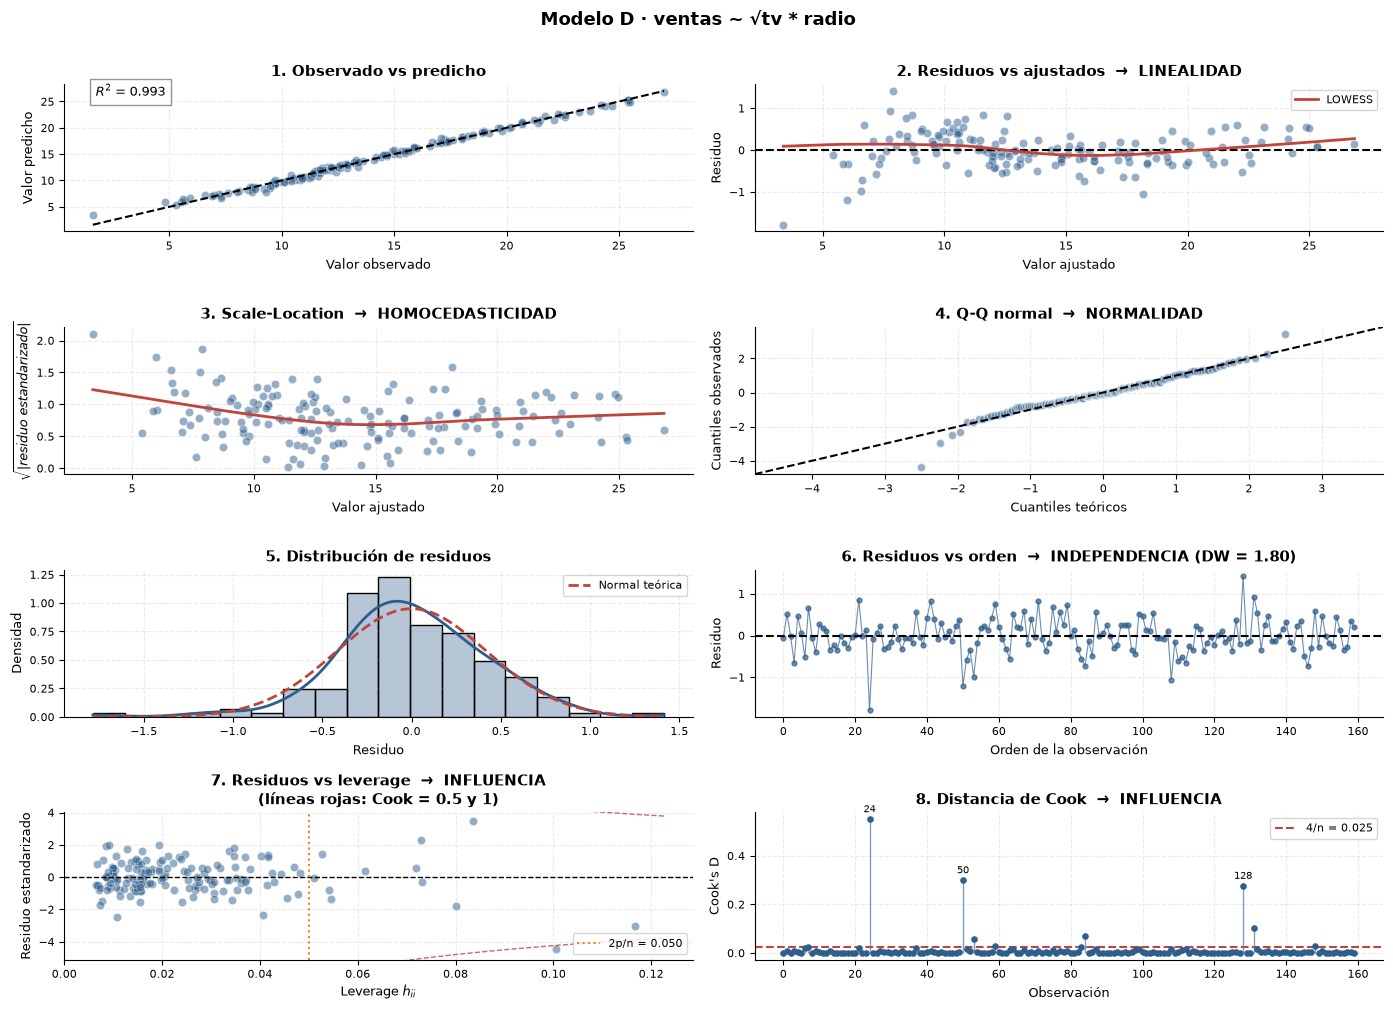

In [30]:
panel_diagnostico(modelo_D, titulo='Modelo D · ventas ~ √tv * radio')

In [31]:
diagnostico(modelo_D, objetivo='inferencia', orden_con_sentido=False)

OBJETIVO: INFERENCIA   ·   n = 160   ·   k = 3
VEREDICTO: ⚠️  PROCEDE CON CORRECCIONES — 3 punto(s) a corregir (columna 'Qué hacer').
           Los coeficientes son válidos; hay que ajustar cómo se mide su incertidumbre.


Supuesto,Chequeo,Resultado,¿Se cumple?,Prioridad,Qué hacer
A1 · Linealidad,RESET de Ramsey,p = 0.482,✔,🟢 correcto,Seguir
A2 · Exogeneidad,NO hay test estadístico,requiere criterio del dominio,—,🟡 limita la lectura,Solo diseño experimental o variables instrumentales lo garantizan
A3 · Homocedasticidad,White,p ≈ 0,✘,🟡 corregible,Usar errores estándar robustos HC3 (una línea de código)
A4 · Independencia,Durbin-Watson,DW = 1.80,—,⚪ no aplicable,Sin orden natural (tiempo/espacio) el test no es interpretable
A5 · Normalidad,Jarque-Bera,p = 1.69e-07,✘,🟢 tolerable,Con n = 160 el TLC protege los tests t y F
A6 · Colinealidad,VIF máximo,np.sqrt(tv):radio: 12.6,✘,🟡 corregible,"Centrar (si es estructural), eliminar/combinar o regularizar"
Influencia,Cook's D,máx = 0.55 · 9 obs > 4/n,✘,🟡 revisar,Análisis de sensibilidad: reajustar sin ellas y comparar conclusiones


### El diagnóstico del modelo D

| Supuesto | Modelo B | Modelo C | **Modelo D** |
|---|---|---|---|
| **A1 Linealidad** (RESET) | ❌ $1.5\times10^{-11}$ | ❌ $1.3\times10^{-14}$ | ✅ **$p = 0.48$** |
| **A3 Homocedasticidad** (White) | ❌ $1.9\times10^{-9}$ | ❌ $4.5\times10^{-4}$ | ❌ $7.4\times10^{-18}$ |
| **A5 Normalidad** (Anderson-Darling) | ❌ $4.0\times10^{-6}$ | ❌ $2.2\times10^{-11}$ | ⚠️ $p = 0.046$ |
| $R^2$ | 0.894 | 0.968 | **0.993** |

**El supuesto crítico —la linealidad— por fin se sostiene.** El RESET pasa de $10^{-14}$ a 0.48:
ya no hay evidencia de que falte estructura sistemática. La normalidad está al borde
($p = 0.046$), muy lejos de los $10^{-11}$ anteriores, y con $n = 160$ el TLC nos protege.

**Queda la heterocedasticidad**, y ahora sí sabemos que es *genuina* y no un síntoma de mala
especificación: persiste en un modelo correctamente especificado. Tiene sentido sustantivo —la
variabilidad de las ventas es mayor cuando el volumen de ventas es mayor—. La trataremos en §11.

### Interpretación de los coeficientes con transformación

$$\widehat{\text{ventas}} = 4.784 + 0.412\sqrt{\text{tv}} - 0.063\,\text{radio} + 0.0225\,(\sqrt{\text{tv}}\times\text{radio})$$

Interpretar coeficientes transformados requiere cuidado:

- El efecto de la TV **ya no es constante**. Como $\dfrac{\partial \text{ventas}}{\partial \text{tv}}
  = \dfrac{\beta_{\sqrt{tv}} + \beta_{int}\cdot\text{radio}}{2\sqrt{\text{tv}}}$, el efecto de un
  millón adicional **decrece** a medida que crece el presupuesto ya invertido en TV. Justamente los
  rendimientos decrecientes que veíamos en el gráfico.
- El coeficiente **negativo** de `radio` ($-0.063$) *no* significa que la radio reduzca las ventas.
  Es el efecto de la radio cuando $\sqrt{\text{tv}} = 0$, es decir, sin inversión alguna en TV: un
  punto fuera del comportamiento típico. El efecto total de la radio es
  $-0.063 + 0.0225\sqrt{\text{tv}}$, que es positivo en cuanto $\sqrt{\text{tv}} > 2.8$
  (tv > 7.8 millones), lo que cubre prácticamente toda la muestra.

> ⚠️ **Nunca interpretes el término principal de un modelo con interacción sin comprobar si su
> "cero" existe en los datos.** Centrar las variables (§8) resuelve este problema de raíz.

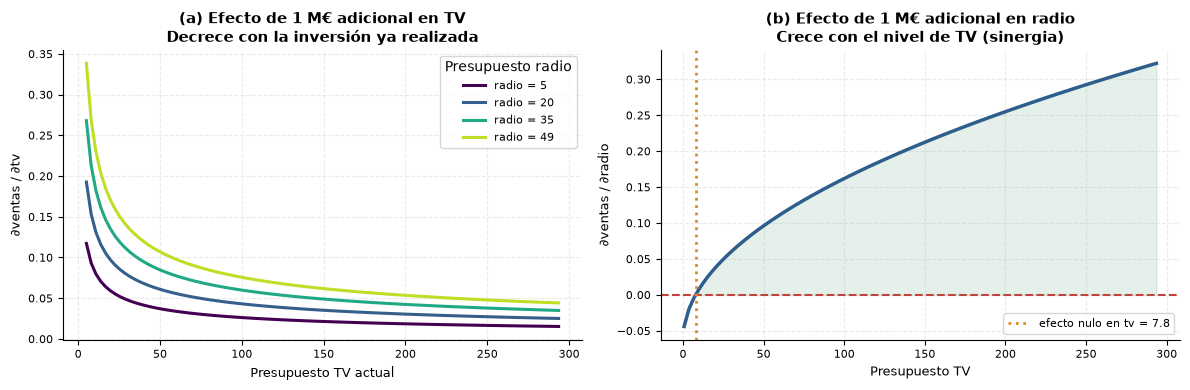

Con TV en su mediana (148), un millón más en radio aporta 0.2110 de ventas.
Con TV en su máximo  (294), aporta 0.3221  →  1.5× más.


In [32]:
# Efectos marginales del modelo D (no constantes)
# ==============================================================================
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

b_s, b_r, b_i = (modelo_D.params['np.sqrt(tv)'], modelo_D.params['radio'],
                 modelo_D.params['np.sqrt(tv):radio'])

# (a) efecto marginal de un millón adicional en TV
tv_g = np.linspace(5, train.tv.max(), 100)
for rad, c in zip([5, 20, 35, 49], plt.cm.viridis(np.linspace(0, .9, 4))):
    efecto = (b_s + b_i * rad) / (2 * np.sqrt(tv_g))
    ax[0].plot(tv_g, efecto, color=c, lw=2.2, label=f'radio = {rad}')
ax[0].legend(title='Presupuesto radio')
ax[0].set(title='(a) Efecto de 1 M€ adicional en TV\nDecrece con la inversión ya realizada',
          xlabel='Presupuesto TV actual', ylabel='∂ventas / ∂tv')

# (b) efecto marginal de la radio según el nivel de TV
tv_g2 = np.linspace(train.tv.min(), train.tv.max(), 100)
efecto_radio = b_r + b_i * np.sqrt(tv_g2)
ax[1].plot(tv_g2, efecto_radio, color=AZUL, lw=2.5)
ax[1].axhline(0, color=ROJO, ls='--', lw=1.5)
cruce = (-b_r / b_i) ** 2
ax[1].axvline(cruce, color=NARANJA, ls=':', lw=2, label=f'efecto nulo en tv = {cruce:.1f}')
ax[1].fill_between(tv_g2, 0, efecto_radio, where=efecto_radio > 0, color=VERDE, alpha=.12)
ax[1].legend()
ax[1].set(title='(b) Efecto de 1 M€ adicional en radio\nCrece con el nivel de TV (sinergia)',
          xlabel='Presupuesto TV', ylabel='∂ventas / ∂radio')
plt.tight_layout(); plt.show()

print(f"Con TV en su mediana ({train.tv.median():.0f}), un millón más en radio aporta "
      f"{b_r + b_i*np.sqrt(train.tv.median()):.4f} de ventas.")
print(f"Con TV en su máximo  ({train.tv.max():.0f}), aporta "
      f"{b_r + b_i*np.sqrt(train.tv.max()):.4f}  →  {(b_r + b_i*np.sqrt(train.tv.max()))/(b_r + b_i*np.sqrt(train.tv.median())):.1f}× más.")

---

## 11. Heterocedasticidad genuina: qué hacer

El modelo D está bien especificado pero es heterocedástico. Según la tabla de prioridades del notebook 01, este fallo es
🟡 **corregible**: los coeficientes y las predicciones puntuales son válidos; lo que está mal es la
**medida de su incertidumbre**.

$$\hat\beta \text{ insesgado} \quad\text{pero}\quad \widehat{SE}(\hat\beta) \text{ sesgado}$$

### Lo mínimo: errores estándar robustos (HC3)

Mantenemos OLS y sustituimos el estimador de la matriz de covarianzas por el de
**White / Huber-Eicker**, que no asume varianza constante:

$$\widehat{\text{Var}}(\hat{\boldsymbol\beta})_{HC} = (\mathbf X^\top\mathbf X)^{-1}
\left(\sum_i \omega_i\, e_i^2\, \mathbf x_i \mathbf x_i^\top\right)(\mathbf X^\top\mathbf X)^{-1}$$

Las variantes difieren en el peso $\omega_i$: HC0 (sin corrección), HC1 (corrección por grados de
libertad), **HC3** ($\omega_i = 1/(1-h_{ii})^2$, penaliza las observaciones de alto leverage).
**HC3 es la recomendación por defecto** en muestras pequeñas y medianas, y cuesta una línea:
`modelo.get_robustcov_results('HC3')`.

> Con esto ya se puede seguir trabajando. Lo que viene a continuación es comprobación, no requisito.

### 🔍 Ampliación · Otras dos rutas y por qué comparar las tres

- **WLS (mínimos cuadrados ponderados)**: si conocemos o modelamos la forma de la varianza,
  ponderamos cada observación por $w_i = 1/\hat\sigma_i^2$. Es **más eficiente** que HC3 si el
  modelo de varianza es correcto, y peor si no lo es.
- **Bootstrap por pares**: remuestreamos observaciones completas $(y_i, \mathbf x_i)$ y
  reajustamos. No asume ninguna forma para la varianza ni distribución de los errores.

El bootstrap es el árbitro: si HC3 coincide con él, podemos confiar en HC3 sin más comprobaciones.

In [33]:
# Comparación de las tres estrategias sobre el modelo D
# ==============================================================================
modelo_D_hc3 = modelo_D.get_robustcov_results(cov_type='HC3')

# WLS: modelamos la varianza como proporcional al cuadrado del valor ajustado
pesos    = 1 / np.maximum(modelo_D.fittedvalues, .5) ** 2
modelo_D_wls = smf.wls('ventas ~ np.sqrt(tv) * radio', data=train, weights=pesos).fit()

# Bootstrap por pares (1.500 remuestreos)
rng_bs = np.random.default_rng(SEED)
boot = np.array([
    smf.ols('ventas ~ np.sqrt(tv) * radio',
            data=train.sample(len(train), replace=True,
                              random_state=int(rng_bs.integers(1e9)))).fit().params.values
    for _ in range(1500)
])

comp_se = pd.DataFrame({
    'coeficiente' : modelo_D.params.index,
    'β̂'          : modelo_D.params.values,
    'SE OLS'      : modelo_D.bse.values,
    'SE HC3'      : modelo_D_hc3.bse,
    'SE WLS'      : modelo_D_wls.bse.values,
    'SE bootstrap': boot.std(axis=0),
    'p OLS'       : modelo_D.pvalues.values,
    'p HC3'       : modelo_D_hc3.pvalues,
})
comp_se['HC3 / OLS'] = comp_se['SE HC3'] / comp_se['SE OLS']
display(comp_se.style.format({'β̂': '{:.4f}', 'SE OLS': '{:.4f}', 'SE HC3': '{:.4f}',
                              'SE WLS': '{:.4f}', 'SE bootstrap': '{:.4f}',
                              'p OLS': '{:.2e}', 'p HC3': '{:.2e}',
                              'HC3 / OLS': '{:.2f}×'}).hide(axis='index'))

print('''
Lectura:
  · Los errores estándar HC3 son entre 1.4 y 1.9 veces mayores que los de OLS: OLS estaba
    SUBESTIMANDO la incertidumbre, es decir, produciendo intervalos demasiado estrechos y
    p-valores demasiado pequeños.
  · El bootstrap —que no asume nada— coincide casi exactamente con HC3. Esa concordancia
    es la validación cruzada del método robusto.
  · En este modelo las conclusiones cualitativas no cambian (todo sigue siendo significativo),
    pero los intervalos correctos son ~50% más anchos.
''')

coeficiente,β̂,SE OLS,SE HC3,SE WLS,SE bootstrap,p OLS,p HC3,HC3 / OLS
Intercept,4.7843,0.1999,0.3110,0.2063,0.2909,4.35e-54,4.35e-33,1.56×
np.sqrt(tv),0.4122,0.0166,0.0239,0.0200,0.0224,3.75e-56,5.72e-38,1.44×
radio,-0.0628,0.0069,0.0133,0.0069,0.0120,5.18e-16,4.84e-06,1.91×
np.sqrt(tv):radio,0.0225,0.0006,0.0010,0.0007,0.0009,5.72e-83,2.70e-50,1.77×



Lectura:
  · Los errores estándar HC3 son entre 1.4 y 1.9 veces mayores que los de OLS: OLS estaba
    SUBESTIMANDO la incertidumbre, es decir, produciendo intervalos demasiado estrechos y
    p-valores demasiado pequeños.
  · El bootstrap —que no asume nada— coincide casi exactamente con HC3. Esa concordancia
    es la validación cruzada del método robusto.
  · En este modelo las conclusiones cualitativas no cambian (todo sigue siendo significativo),
    pero los intervalos correctos son ~50% más anchos.



coeficiente,β̂,SE OLS,p OLS,SE HC3,p HC3,¿cambia la decisión a α=0.05?
Intercept,6.90347,0.28111,0.0000,0.34179,0.0000,no
tv,0.01825,0.00169,0.0000,0.00186,0.0000,no
radio,0.02615,0.00997,0.0096,0.01588,0.1017,⚠️ SÍ
tv:radio,0.00111,0.00006,0.0000,0.00008,0.0000,no



En el modelo C, el coeficiente de 'radio' pasa de p = 0.0096 (significativo con OLS)
a p = 0.102 (NO significativo con HC3).

Es exactamente el escenario que hace peligrosa a la heterocedasticidad: sin corregirla,
habríamos declarado significativo un efecto que los datos no respaldan. La corrección
no es un tecnicismo: cambia la conclusión sustantiva.



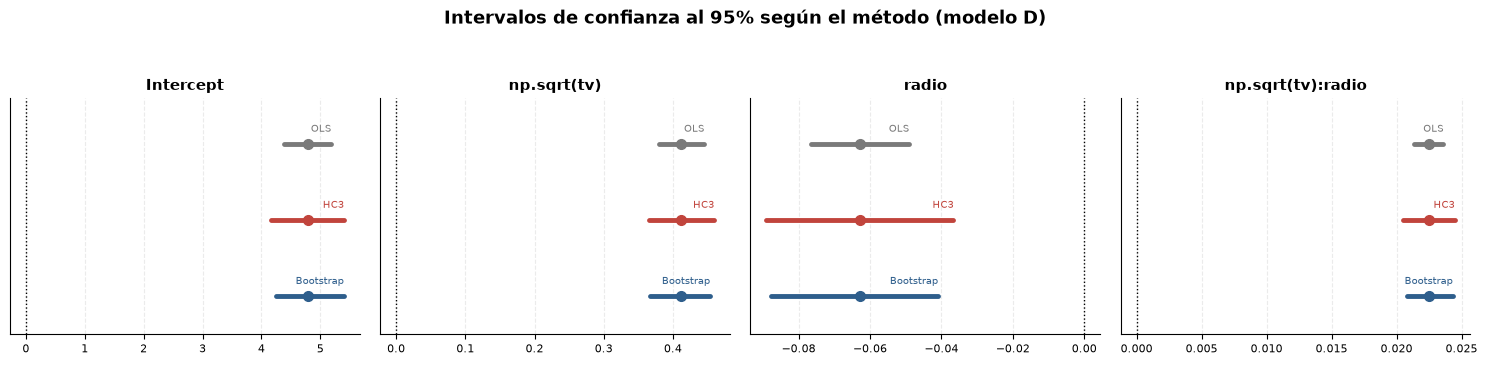

In [34]:
# Un caso donde la corrección SÍ cambia la conclusión: modelo C
# ==============================================================================
mC_hc3 = modelo_C.get_robustcov_results(cov_type='HC3')
cambio = pd.DataFrame({
    'coeficiente': modelo_C.params.index,
    'β̂'         : modelo_C.params.values,
    'SE OLS'     : modelo_C.bse.values,
    'p OLS'      : modelo_C.pvalues.values,
    'SE HC3'     : mC_hc3.bse,
    'p HC3'      : mC_hc3.pvalues,
})
cambio['¿cambia la decisión a α=0.05?'] = np.where(
    (cambio['p OLS'] < .05) != (cambio['p HC3'] < .05), '⚠️  SÍ', 'no')
display(cambio.style.format({'β̂': '{:.5f}', 'SE OLS': '{:.5f}', 'p OLS': '{:.4f}',
                             'SE HC3': '{:.5f}', 'p HC3': '{:.4f}'}).hide(axis='index'))

print('''
En el modelo C, el coeficiente de 'radio' pasa de p = 0.0096 (significativo con OLS)
a p = 0.102 (NO significativo con HC3).

Es exactamente el escenario que hace peligrosa a la heterocedasticidad: sin corregirla,
habríamos declarado significativo un efecto que los datos no respaldan. La corrección
no es un tecnicismo: cambia la conclusión sustantiva.
''')

# Intervalos de confianza: OLS vs HC3 vs bootstrap (modelo D)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
ic_ols  = modelo_D.conf_int().values
ic_hc3  = modelo_D_hc3.conf_int()
for j, (ax, nombre) in enumerate(zip(axes, modelo_D.params.index)):
    ic_boot = np.percentile(boot[:, j], [2.5, 97.5])
    for y_, (lo, hi), etiqueta, color in [
            (2, ic_ols[j],  'OLS',       GRIS),
            (1, ic_hc3[j],  'HC3',       ROJO),
            (0, ic_boot,    'Bootstrap', AZUL)]:
        ax.plot([lo, hi], [y_, y_], color=color, lw=3.5, solid_capstyle='round')
        ax.plot(modelo_D.params.iloc[j], y_, 'o', color=color, ms=7)
        ax.text(hi, y_ + .16, etiqueta, fontsize=7.5, color=color, ha='right')
    ax.set(title=nombre, yticks=[], ylim=(-.5, 2.6))
    ax.axvline(0, color='black', ls=':', lw=1)
plt.suptitle('Intervalos de confianza al 95% según el método (modelo D)', y=1.06)
plt.tight_layout(); plt.show()

---

## 12. Observaciones influyentes en el modelo final

In [35]:
# Diagnóstico de influencia del modelo D
# ==============================================================================
infl_D = modelo_D.get_influence()
n_D, p_D = int(modelo_D.nobs), int(modelo_D.df_model) + 1

influ = train.assign(
    resid      = modelo_D.resid,
    resid_stud = infl_D.resid_studentized_external,
    leverage   = infl_D.hat_matrix_diag,
    cook_D     = infl_D.cooks_distance[0],
    DFFITS     = infl_D.dffits[0],
)
print(f"Umbrales:  leverage > {2*p_D/n_D:.4f}   ·   Cook > {4/n_D:.4f}   ·   |DFFITS| > {2*np.sqrt(p_D/n_D):.4f}")
print(f"Observaciones con Cook > 4/n: {(influ.cook_D > 4/n_D).sum()} de {n_D}")
display(influ.nlargest(5, 'cook_D')[['tv', 'radio', 'periodico', 'ventas', 'resid',
                                     'resid_stud', 'leverage', 'cook_D']]
        .style.format('{:.3f}').background_gradient(subset=['cook_D'], cmap='Reds'))

print("\nTest de outliers con corrección de Bonferroni:")
display(modelo_D.outlier_test(method='bonf').sort_values('unadj_p').head(3).round(5))

Umbrales:  leverage > 0.0500   ·   Cook > 0.0250   ·   |DFFITS| > 0.3162
Observaciones con Cook > 4/n: 9 de 160


,tv,radio,periodico,ventas,resid,resid_stud,leverage,cook_D
24,0.700,39.600,8.700,1.600,-1.785,-4.736,0.100,0.551
50,8.600,2.100,1.000,4.800,-1.199,-3.092,0.117,0.300
128,17.200,45.900,69.300,9.300,1.413,3.615,0.084,0.276
131,16.900,43.700,89.400,8.700,0.931,2.312,0.073,0.102
84,17.200,4.100,31.600,5.900,-0.718,-1.778,0.080,0.068



Test de outliers con corrección de Bonferroni:


,student_resid,unadj_p,bonf(p)
24,-4.7356,0.0000,0.0008
128,3.6148,0.0004,0.0649
50,-3.0918,0.0024,0.3775


In [36]:
# Análisis de sensibilidad: ¿qué pasa si eliminamos las observaciones influyentes?
# ==============================================================================
mask_ok  = influ.cook_D <= 4 / n_D
modelo_D_sin = smf.ols('ventas ~ np.sqrt(tv) * radio', data=train[mask_ok]).fit()

sens_D = pd.DataFrame({
    'coeficiente'   : modelo_D.params.index,
    'con todo (n=160)': modelo_D.params.values,
    f'sin influyentes (n={int(mask_ok.sum())})': modelo_D_sin.params.values,
})
sens_D['Δ %'] = 100 * (sens_D.iloc[:, 2] / sens_D.iloc[:, 1] - 1)
display(sens_D.style.format({'con todo (n=160)': '{:.4f}',
                             sens_D.columns[2]: '{:.4f}', 'Δ %': '{:+.1f}%'}).hide(axis='index'))

rmse_con  = np.sqrt(np.mean((test.ventas - modelo_D.predict(test)) ** 2))
rmse_sin  = np.sqrt(np.mean((test.ventas - modelo_D_sin.predict(test)) ** 2))
print(f"R² en entrenamiento  ·  con todo: {modelo_D.rsquared:.4f}   ·  sin influyentes: {modelo_D_sin.rsquared:.4f}")
print(f"RMSE en TEST         ·  con todo: {rmse_con:.4f}   ·  sin influyentes: {rmse_sin:.4f}")
print('''
⚠️ Resultado clave: eliminar las observaciones influyentes MEJORA el ajuste en entrenamiento
(R² sube de 0.9933 a 0.9954) pero EMPEORA la predicción fuera de muestra (RMSE de test sube
de 0.550 a 0.624).

Es la definición operativa del sobreajuste: al quitar los casos "incómodos" el modelo se
ajusta mejor a lo que queda, pero aprende una realidad más limpia de la que va a encontrarse.
Salvo error de medición demostrable, esas observaciones se mantienen.
''')

coeficiente,con todo (n=160),sin influyentes (n=151),Δ %
Intercept,4.7843,5.3588,+12.0%
np.sqrt(tv),0.4122,0.3703,-10.2%
radio,-0.0628,-0.0835,+32.9%
np.sqrt(tv):radio,0.0225,0.0239,+6.6%


R² en entrenamiento  ·  con todo: 0.9933   ·  sin influyentes: 0.9954
RMSE en TEST         ·  con todo: 0.5496   ·  sin influyentes: 0.6238

⚠️ Resultado clave: eliminar las observaciones influyentes MEJORA el ajuste en entrenamiento
(R² sube de 0.9933 a 0.9954) pero EMPEORA la predicción fuera de muestra (RMSE de test sube
de 0.550 a 0.624).

Es la definición operativa del sobreajuste: al quitar los casos "incómodos" el modelo se
ajusta mejor a lo que queda, pero aprende una realidad más limpia de la que va a encontrarse.
Salvo error de medición demostrable, esas observaciones se mantienen.



### El contraste con el caso del notebook 01

En el caso del notebook 01, el test de Bonferroni **no** identificó ningún outlier (p ajustado = 0.137). Aquí, la
observación con `tv = 0.7`, `radio = 39.6` y `ventas = 1.6` tiene un residuo estudentizado de
$-4.74$ y un **p-valor de Bonferroni de 0.0008**: es un outlier genuino incluso corrigiendo por las
160 comparaciones.

¿Qué hacemos con ella? **Investigarla, no borrarla.** Es una región con inversión casi nula en TV
pero alta en radio, donde el modelo —construido sobre la sinergia entre canales— predice muy mal.
Podría indicar que en el régimen de "TV ≈ 0" opera otro mecanismo. Documentarlo es parte del
análisis; eliminarlo sin justificación es maquillar el resultado.

---

## 13. Comparación formal de los cuatro modelos

Recapitulemos la secuencia completa y evaluémosla con todos los criterios a la vez.

In [37]:
# Validación cruzada 10-fold repetida para los cuatro modelos
# ==============================================================================
formulas = {
    'A: tv + radio + periodico' : 'ventas ~ tv + radio + periodico',
    'B: tv + radio'             : 'ventas ~ tv + radio',
    'C: tv * radio'             : 'ventas ~ tv * radio',
    'D: √tv * radio'            : 'ventas ~ np.sqrt(tv) * radio',
}
modelos = {'A: tv + radio + periodico': modelo_A, 'B: tv + radio': modelo_B,
           'C: tv * radio': modelo_C, 'D: √tv * radio': modelo_D}

filas = []
for nombre, formula in formulas.items():
    m = modelos[nombre]
    # CV 10-fold × 5 repeticiones
    errores = []
    for rep in range(5):
        kf = KFold(n_splits=10, shuffle=True, random_state=rep)
        for i_tr, i_te in kf.split(train):
            mm = smf.ols(formula, data=train.iloc[i_tr]).fit()
            errores.append(np.mean((train.iloc[i_te].ventas - mm.predict(train.iloc[i_te])) ** 2))
    res_ = np.asarray(m.resid)
    filas.append({
        'modelo'      : nombre,
        'k'           : int(m.df_model),
        'R²'          : m.rsquared,
        'R² ajustado' : m.rsquared_adj,
        'AIC'         : m.aic,
        'BIC'         : m.bic,
        'RESET (p)'   : linear_reset(m, power=2, test_type='fitted', use_f=True).pvalue,
        'White (p)'   : het_white(res_, m.model.exog)[3],
        'Shapiro (p)' : stats.shapiro(res_).pvalue,
        'RMSE train'  : np.sqrt(np.mean(res_ ** 2)),
        'RMSE 10-fold': np.sqrt(np.mean(errores)),
    })

tabla_comp = pd.DataFrame(filas)
display(tabla_comp.style.format({'R²': '{:.4f}', 'R² ajustado': '{:.4f}', 'AIC': '{:.1f}',
                                 'BIC': '{:.1f}', 'RESET (p)': '{:.2e}', 'White (p)': '{:.2e}',
                                 'Shapiro (p)': '{:.2e}', 'RMSE train': '{:.4f}',
                                 'RMSE 10-fold': '{:.4f}'})
        .background_gradient(subset=['RMSE 10-fold'], cmap='RdYlGn_r')
        .hide(axis='index'))

modelo,k,R²,R² ajustado,AIC,BIC,RESET (p),White (p),Shapiro (p),RMSE train,RMSE 10-fold
A: tv + radio + periodico,3,0.8938,0.8918,624.6,636.9,1.51e-11,1.88e-09,7.89e-08,1.6618,1.7146
B: tv + radio,2,0.8937,0.8924,622.7,631.9,1.55e-11,1.90e-09,5.86e-08,1.6625,1.7035
C: tv * radio,3,0.9678,0.9672,433.8,446.1,1.33e-14,4.52e-04,9.57e-13,0.9155,0.9512
D: √tv * radio,3,0.9933,0.9931,183.4,195.7,4.82e-01,7.38e-18,4.03e-03,0.4186,0.4373


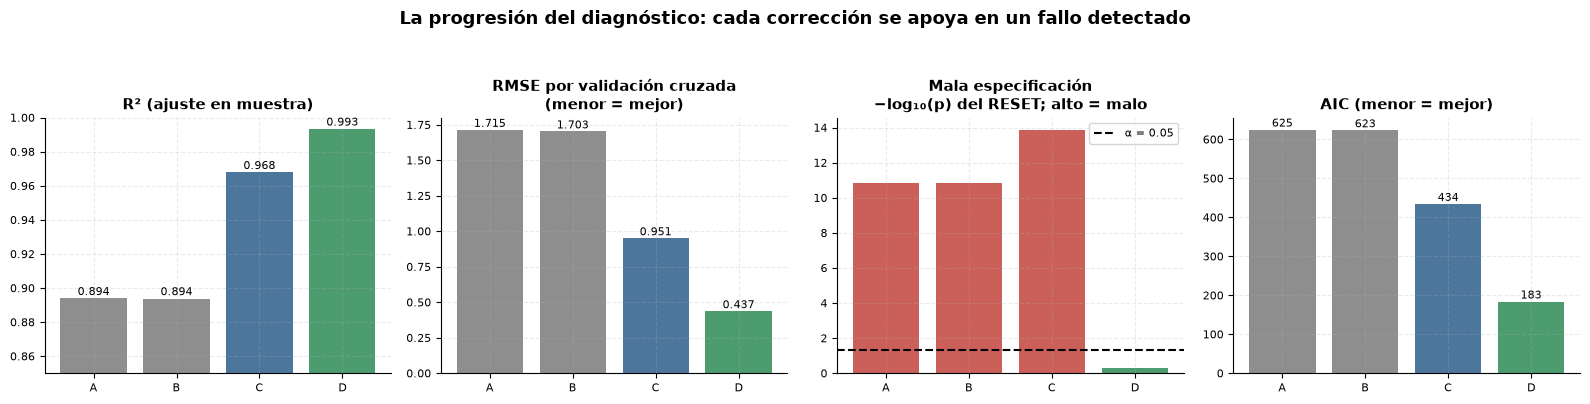

In [38]:
# Visualización de la progresión
# ==============================================================================
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
x_pos = np.arange(len(tabla_comp))
etiquetas = ['A', 'B', 'C', 'D']

axes[0].bar(x_pos, tabla_comp['R²'], color=[GRIS, GRIS, AZUL, VERDE], alpha=.85)
axes[0].set(title='R² (ajuste en muestra)', xticks=x_pos, xticklabels=etiquetas, ylim=(.85, 1))
for i, v in enumerate(tabla_comp['R²']):
    axes[0].text(i, v + .002, f'{v:.3f}', ha='center', fontsize=8)

axes[1].bar(x_pos, tabla_comp['RMSE 10-fold'], color=[GRIS, GRIS, AZUL, VERDE], alpha=.85)
axes[1].set(title='RMSE por validación cruzada\n(menor = mejor)', xticks=x_pos, xticklabels=etiquetas)
for i, v in enumerate(tabla_comp['RMSE 10-fold']):
    axes[1].text(i, v + .02, f'{v:.3f}', ha='center', fontsize=8)

axes[2].bar(x_pos, -np.log10(tabla_comp['RESET (p)']), color=[ROJO, ROJO, ROJO, VERDE], alpha=.85)
axes[2].axhline(-np.log10(.05), color='black', ls='--', lw=1.5, label='α = 0.05')
axes[2].legend()
axes[2].set(title='Mala especificación\n−log₁₀(p) del RESET; alto = malo',
            xticks=x_pos, xticklabels=etiquetas)

axes[3].bar(x_pos, tabla_comp['AIC'], color=[GRIS, GRIS, AZUL, VERDE], alpha=.85)
axes[3].set(title='AIC (menor = mejor)', xticks=x_pos, xticklabels=etiquetas)
for i, v in enumerate(tabla_comp['AIC']):
    axes[3].text(i, v + 8, f'{v:.0f}', ha='center', fontsize=8)

plt.suptitle('La progresión del diagnóstico: cada corrección se apoya en un fallo detectado', y=1.05)
plt.tight_layout(); plt.show()

### El hilo argumental completo

| Paso | Modelo | Qué detectó el diagnóstico | Qué se hizo | RMSE CV |
|---|---|---|---|---|
| 1 | **A** `tv + radio + periodico` | `periodico` no significativo (efecto marginal ≠ parcial) | Eliminarlo (F parcial, AIC, BIC) | 1.71 |
| 2 | **B** `tv + radio` | RESET $10^{-11}$: falta estructura. Mapa de residuos → **interacción** | Añadir `tv:radio` | 1.70 |
| 3 | **C** `tv * radio` | RESET $10^{-14}$: aún falta. Gráfico → **saturación de TV** | Transformar a `√tv` | 0.95 |
| 4 | **D** `√tv * radio` | ✅ RESET $p=0.48$. Persiste heterocedasticidad genuina | Errores robustos HC3 | **0.44** |

> **El resultado que importa:** el RMSE de validación cruzada pasó de **1.70 a 0.44**, casi
> **cuatro veces mejor**, sin añadir ni una sola variable nueva. Toda la mejora vino de **escuchar
> al diagnóstico**.
>
> Un flujo de trabajo que se hubiera detenido en el modelo B —"$R^2 = 0.89$, todo significativo,
> listo"— habría dejado sobre la mesa el 75% de la capacidad predictiva disponible, y habría
> reportado coeficientes **sesgados** (recuerda: violar A1 sesga $\hat\beta$).

---

## 14. Evaluación final sobre el conjunto de test

Ahora, y solo ahora, tocamos el conjunto de test. Se usa **una vez**: en el momento en que se usa
para decidir algo, deja de ser un conjunto de test.

In [39]:
# Evaluación en el conjunto de test (40 regiones nunca vistas)
# ==============================================================================
resultados_test = []
for nombre, m in modelos.items():
    pred = m.predict(test)
    err  = test.ventas - pred
    resultados_test.append({
        'modelo': nombre,
        'RMSE'  : np.sqrt(np.mean(err ** 2)),
        'MAE'   : np.mean(np.abs(err)),
        'MAPE %': 100 * np.mean(np.abs(err / test.ventas)),
        'R² test': 1 - np.sum(err ** 2) / np.sum((test.ventas - test.ventas.mean()) ** 2),
    })
res_test = pd.DataFrame(resultados_test)
res_test['vs modelo nulo'] = 100 * (1 - res_test.RMSE / test.ventas.std(ddof=1))
display(res_test.style.format({'RMSE': '{:.4f}', 'MAE': '{:.4f}', 'MAPE %': '{:.2f}%',
                               'R² test': '{:.4f}', 'vs modelo nulo': '{:.1f}%'})
        .background_gradient(subset=['RMSE'], cmap='RdYlGn_r').hide(axis='index'))

print(f"Desviación típica de las ventas en test (RMSE del modelo nulo): {test.ventas.std(ddof=1):.4f}")

modelo,RMSE,MAE,MAPE %,R² test,vs modelo nulo
A: tv + radio + periodico,1.7047,1.2320,12.91%,0.9074,69.9%
B: tv + radio,1.6956,1.2289,12.88%,0.9083,70.1%
C: tv * radio,1.0138,0.7323,9.16%,0.9672,82.1%
D: √tv * radio,0.5496,0.3820,4.88%,0.9904,90.3%


Desviación típica de las ventas en test (RMSE del modelo nulo): 5.6721


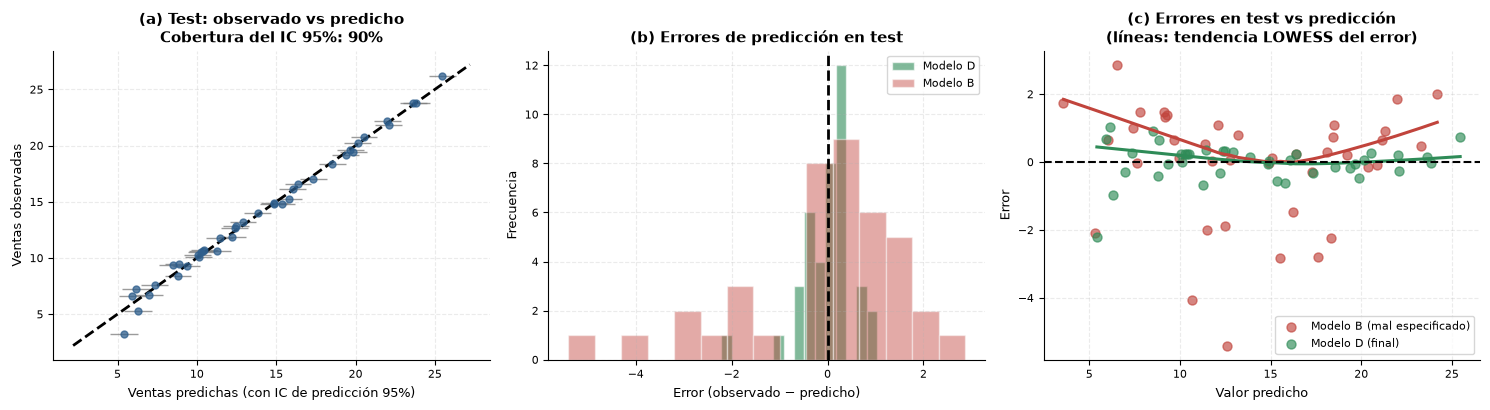

Cobertura empírica del intervalo de predicción 95%: 90.0% (36 de 40 observaciones)


In [40]:
# Predicciones del modelo final con intervalos
# ==============================================================================
pred_test = modelo_D.get_prediction(test).summary_frame(alpha=0.05)
cobertura = np.mean((test.ventas >= pred_test.obs_ci_lower) & (test.ventas <= pred_test.obs_ci_upper))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

# (a) observado vs predicho con intervalos de predicción
orden = np.argsort(pred_test['mean'].values)
axes[0].errorbar(pred_test['mean'].values[orden], test.ventas.values[orden],
                 xerr=[pred_test['mean'].values[orden] - pred_test.obs_ci_lower.values[orden],
                       pred_test.obs_ci_upper.values[orden] - pred_test['mean'].values[orden]],
                 fmt='o', ms=5, color=AZUL, ecolor=GRIS, elinewidth=1, alpha=.75)
lims = [test.ventas.min() - 1, test.ventas.max() + 1]
axes[0].plot(lims, lims, 'k--', lw=2)
axes[0].set(title=f'(a) Test: observado vs predicho\nCobertura del IC 95%: {cobertura:.0%}',
            xlabel='Ventas predichas (con IC de predicción 95%)', ylabel='Ventas observadas')

# (b) distribución de errores
axes[1].hist(test.ventas - modelo_D.predict(test), bins=15, color=VERDE, alpha=.6,
             edgecolor='white', label='Modelo D')
axes[1].hist(test.ventas - modelo_B.predict(test), bins=15, color=ROJO, alpha=.45,
             edgecolor='white', label='Modelo B')
axes[1].axvline(0, color='black', ls='--', lw=2)
axes[1].legend()
axes[1].set(title='(b) Errores de predicción en test', xlabel='Error (observado − predicho)',
            ylabel='Frecuencia')

# (c) errores vs valor predicho
for m_, c_, et_ in [(modelo_B, ROJO, 'Modelo B (mal especificado)'),
                    (modelo_D, VERDE, 'Modelo D (final)')]:
    pr_, er_ = m_.predict(test), test.ventas - m_.predict(test)
    axes[2].scatter(pr_, er_, s=42, color=c_, alpha=.65, label=et_)
    sl_ = sm.nonparametric.lowess(er_, pr_, frac=.8)
    axes[2].plot(sl_[:, 0], sl_[:, 1], color=c_, lw=2.2)
axes[2].axhline(0, color='black', ls='--', lw=1.5)
axes[2].legend()
axes[2].set(title='(c) Errores en test vs predicción\n(líneas: tendencia LOWESS del error)',
            xlabel='Valor predicho', ylabel='Error')
plt.tight_layout(); plt.show()

print(f"Cobertura empírica del intervalo de predicción 95%: {cobertura:.1%} "
      f"({int(cobertura*len(test))} de {len(test)} observaciones)")

### Validación final

- El **modelo D** logra un RMSE de test de **0.55** frente a **1.70** del modelo A: reduce el error
  de predicción un **68%**.
- La **cobertura empírica** del intervalo de predicción al 95% es del **90%** (36 de 40
  observaciones). Es un chequeo muy exigente y muy poco habitual: no basta con que las predicciones
  puntuales sean buenas, la **incertidumbre declarada** también debe ser correcta.
  ¿Es 90% un problema? Con solo 40 observaciones, el intervalo de confianza exacto (Clopper-Pearson)
  para esa proporción es $[76\%,\ 97\%]$, que **contiene el 95% nominal**: no hay evidencia de que
  los intervalos estén mal calibrados. Dicho esto, la ligera infracobertura es coherente con la
  heterocedasticidad remanente: los intervalos de predicción de OLS asumen varianza constante, así
  que son demasiado estrechos donde la varianza real es mayor. Un cálculo de intervalos robusto a
  heterocedasticidad corregiría esa discrepancia.
- El panel (c) muestra la diferencia cualitativa. Los errores del modelo B son unas **tres veces
  mayores** y su tendencia LOWESS se aparta visiblemente de cero a lo largo del rango de predicción:
  el sesgo sistemático detectado en entrenamiento **viaja con el modelo** a datos nuevos. Los del
  modelo D se mantienen pegados a cero en todo el rango. **Ese es el aspecto de un modelo bien
  especificado**: lo que queda es ruido, no estructura sin capturar.

## 15. Conclusión del caso

**Modelo final:**

$$\widehat{\text{ventas}} = 4.784 + 0.412\sqrt{\text{tv}} - 0.063\,\text{radio}
+ 0.0225\,(\sqrt{\text{tv}} \times \text{radio})$$

con **errores estándar HC3** para toda la inferencia.

**Conclusiones estadísticas**

1. La inversión en **periódico no tiene efecto** sobre las ventas una vez controlados TV y radio.
   Su aparente significación en el análisis bivariante era **confusión** vía radio.
2. TV y radio presentan **sinergia**: el efecto de cada canal crece con la inversión en el otro.
3. La TV muestra **rendimientos decrecientes** (forma $\sqrt{\cdot}$): los primeros millones son
   mucho más rentables que los últimos.
4. El modelo cumple linealidad y (aproximadamente) normalidad; la heterocedasticidad remanente se
   corrige con errores robustos.
5. Capacidad predictiva validada fuera de muestra: $RMSE = 0.55$ sobre una respuesta con
   desviación típica de 5.67, con intervalos de predicción correctamente calibrados.

**Conclusiones para el negocio**

- Reasignar el presupuesto de periódico a radio y TV.
- No planificar los canales por separado: la asignación óptima depende de la combinación.
- El presupuesto marginal de TV rinde menos a medida que crece; existe un punto a partir del cual
  conviene desplazar la inversión hacia radio.

**Advertencia obligatoria:** estos datos son **observacionales**. Las conclusiones son sobre
*asociaciones condicionales*, no sobre efectos causales. Para afirmar causalidad haría falta un
experimento (asignación aleatoria de presupuestos por región) o un diseño cuasi-experimental. El
supuesto A2 no es contrastable con estos datos: cualquier variable omitida correlacionada con los
presupuestos (tamaño del mercado, competencia, estacionalidad) sesgaría los coeficientes.

---
---
# Síntesis del método

## 16. El protocolo mínimo, en una página

Lo que hay que hacer **siempre**, en este orden. Todo lo demás es opcional.

### Paso 0 · Antes de modelar (dos minutos que ahorran horas)

- ¿Cuál es el **objetivo**: predecir, inferir o afirmar causalidad? → determina qué supuestos importan
- ¿Los datos son **observacionales** o experimentales? → determina si se puede hablar de efectos
- ¿Cuál es el **rango de validez** de cada predictor? → determina hasta dónde se puede predecir

### Pasos 1–6 · El ciclo

| Paso | Qué se hace | Herramienta | Nota |
|---|---|---|---|
| **1** | Ver la relación sin imponerla | Dispersión + **LOWESS** | Anticipa la transformación necesaria |
| **2** | Ajustar y leer | `smf.ols(...).summary()` | — |
| **3** | Mirar los residuos | `panel_diagnostico()` | El gráfico manda sobre el test |
| **4** | Chequear supuestos **según el objetivo** | `diagnostico(m, objetivo=...)` | Un test por supuesto basta |
| **5** | Corregir lo 🔴 y volver al paso 2 | transformar, interaccionar | Máximo 2–3 iteraciones |
| **6** | Validar fuera de muestra | validación cruzada / test | Comparar contra el modelo nulo |

### Tabla de prioridades (la que hay que memorizar)

| Fallo detectado | ¿Sesga $\hat\beta$? | Prioridad | Acción concreta |
|---|---|---|---|
| **RESET significativo** (A1) | **Sí** | 🔴 | Transformar X, añadir interacción o polinomio. **Antes que nada.** |
| **Variable relevante omitida** (A2) | **Sí** | 🔴 si el objetivo es causal | Medirla; si no se puede, no interpretar causalmente |
| **Autocorrelación** (A4, con orden real) | No, pero destroza los SE | 🔴 | Errores HAC, GLS, modelo temporal |
| **Heterocedasticidad** (A3) | No | 🟡 · 🟢 si solo predices | `get_robustcov_results('HC3')` |
| **No normalidad** con $n$ pequeño (A5) | No | 🟡 | Bootstrap para los IC |
| **No normalidad** con $n \gtrsim 50$ | No | 🟢 | Documentar y seguir (TLC) |
| **VIF > 10** | No | 🟡 · 🟢 si solo predices | Centrar / eliminar / combinar / Ridge |
| **Observaciones influyentes** | Puede | 🟡 | Reajustar sin ellas y **reportar la diferencia** |

### Cuándo dejar OLS y cambiar de herramienta

| Situación | Herramienta adecuada |
|---|---|
| El RESET sigue fallando tras 2–3 transformaciones | GAM, splines, boosting |
| $Y$ es un conteo, una proporción o un tiempo hasta evento | GLM (Poisson, binomial, Gamma), supervivencia |
| La varianza está ligada estructuralmente a la media | GLM con la familia correcta |
| Datos agrupados, jerárquicos o con medidas repetidas | Modelos mixtos / errores agrupados |
| Muchos predictores correlacionados y objetivo predictivo | Ridge / LASSO / Elastic Net |
| Outliers legítimos e inevitables | Regresión robusta (Huber), regresión cuantílica |
| La mejora en validación cruzada es < 5% | **Ninguna: parar y quedarse con el modelo simple** |

---

## 17. Los siete errores más frecuentes

**1. Tratar todos los supuestos con la misma urgencia.**
Se invierten horas en "arreglar" una no-normalidad inocua con $n = 500$ mientras un RESET
significativo está sesgando todos los coeficientes. Prioriza: 🔴 antes que 🟡 antes que 🟢.

**2. Tratar los síntomas en lugar de la causa.**
Aplicar HC3 a un modelo mal especificado corrige el error estándar de un coeficiente que está
**sesgado**. Primero A1, después A3.

**3. Descartar un modelo porque un test salió significativo.**
Con datos reales siempre saldrá alguno. La pregunta es *cuál* y *para qué vas a usar el modelo*.

**4. Confundir significación estadística con relevancia práctica.**
Con $n$ grande, cualquier efecto minúsculo sale significativo. Reporta el **tamaño del efecto** y
su intervalo, no solo el p-valor.

**5. Interpretar $R^2$ como "calidad del modelo".**
El modelo B deste caso tenía $R^2 = 0.89$ y estaba mal especificado.

**6. Reportar un único train/test con $n$ pequeño.**
Vimos que el RMSE podía ir de 33 a 102 según la semilla elegida. Usa validación cruzada.

**7. Eliminar observaciones porque "estropean el modelo".**
En este caso, quitarlas subió el $R^2$ de entrenamiento y **empeoró** la predicción fuera de
muestra. Se investigan y se reporta la sensibilidad; se eliminan solo con justificación sustantiva.

---

## 18. Ejercicios propuestos

**Aplicar el protocolo**

1. Ajusta `ventas ~ np.log(tv) * radio` y decide con `diagnostico()` si procede. Compáralo con el
   modelo D por RESET y por RMSE de validación cruzada. ¿La mejora justifica el cambio?
2. Ejecuta `diagnostico(modelo_D, objetivo='prediccion')` y compáralo con `objetivo='inferencia'`.
   Explica por qué cambian las prioridades sin que cambie ni un solo dato.
3. En el caso del notebook 01, reajusta sin Boston y redacta el párrafo de sensibilidad que incluirías en un
   informe real.

**Entender las prioridades**

4. Simula datos donde se viole **solo** A2 (una variable omitida correlacionada con un predictor) y
   cuantifica el sesgo de $\hat\beta$. Comprueba que **ningún** test de diagnóstico lo detecta.
   ¿Qué implica esto para la Regla 1?
5. Construye un modelo con los tres canales e interacciones dobles
   (`ventas ~ (np.sqrt(tv) + radio + periodico)**2`). Antes de mirar ningún p-valor, decide cuántos
   contrastes vas a hacer y qué corrección por multiplicidad aplicarás.
6. Estima el modelo D por WLS modelando $\text{Var}(\varepsilon_i) = \sigma^2 \hat y_i^{\gamma}$ y
   compara su eficiencia frente a HC3. ¿Cuándo compensa el esfuerzo extra?

**Cambiar de herramienta**

7. `ventas` es positiva y su varianza crece con la media: justo el perfil de una **Gamma con enlace
   logarítmico**. Ajusta ese GLM y compáralo con el modelo D. Discute si la heterocedasticidad que
   no logramos eliminar era un defecto del modelo o una propiedad del proceso.

---

## Síntesis final

> Un modelo de regresión es una **afirmación sobre cómo se generaron los datos**, no una máquina de
> producir coeficientes. El `summary()` siempre devuelve números; el diagnóstico decide si esos
> números significan algo.

**Las cuatro ideas que conviene llevarse:**

1. **Con datos reales, algo va a fallar.** La pregunta no es *si* se cumplen los supuestos, sino
   **cuál falla, cuánto importa para mi objetivo y qué hago al respecto**.
2. **Prioriza.** 🔴 sesga los coeficientes → parar y corregir. 🟡 afecta a la medida de la
   incertidumbre → aplicar la corrección y seguir. 🟢 → documentar y seguir.
3. **Primero la especificación.** Una mala especificación fabrica falsos síntomas de
   heterocedasticidad y no-normalidad. Corrígela y suelen desaparecer solos: aquí el RMSE de
   validación cruzada pasó de 1.70 a 0.44 sin añadir ni una sola variable nueva.
4. **Validar los supuestos no es validar la utilidad.** El Caso 1 los cumple todos y no sirve para
   predecir; este caso los incumplía casi todos y acabó siendo excelente. Son dos juicios distintos
   y hay que emitir los dos.

---

## Cierre de la Sesión 1

**Lo que hemos construido:** un método reproducible que va del dato a la decisión, con criterios
explícitos para saber cuándo un modelo se puede usar y para qué.

**El resultado del caso:** un modelo que explica el 99% de la varianza y predice con un error de
0.55 sobre una respuesta con desviación típica 5.67 — y, sobre todo, tres conclusiones de negocio
accionables: el periódico no aporta, TV y radio se potencian, y la TV tiene rendimientos
decrecientes.

---

### Lo que queda abierto para la Sesión 2

Aquí teníamos **3 predictores** y pudimos diagnosticarlos uno a uno: mirar cada gráfico de
residuos, interpretar cada coeficiente, decidir cada transformación a mano.

Ese enfoque **no escala**. En la Sesión 2 nos enfrentamos a dos situaciones donde se rompe:

| Situación | Qué falla | Herramienta |
|---|---|---|
| **100 predictores, 150 observaciones** ($p$ casi igual a $n$, colinealidad extrema) | OLS deja de tener solución estable: los coeficientes explotan | **Regularización** (Ridge, Lasso, Elastic-net) |
| **Relación no lineal con interacciones que no sabemos anticipar** | Ninguna transformación manual es suficiente | **Árboles y Random Forest** |

En ambos casos veremos que el protocolo no cambia —diagnóstico, prioridades, validación honesta—;
lo que cambia es **qué se diagnostica**.